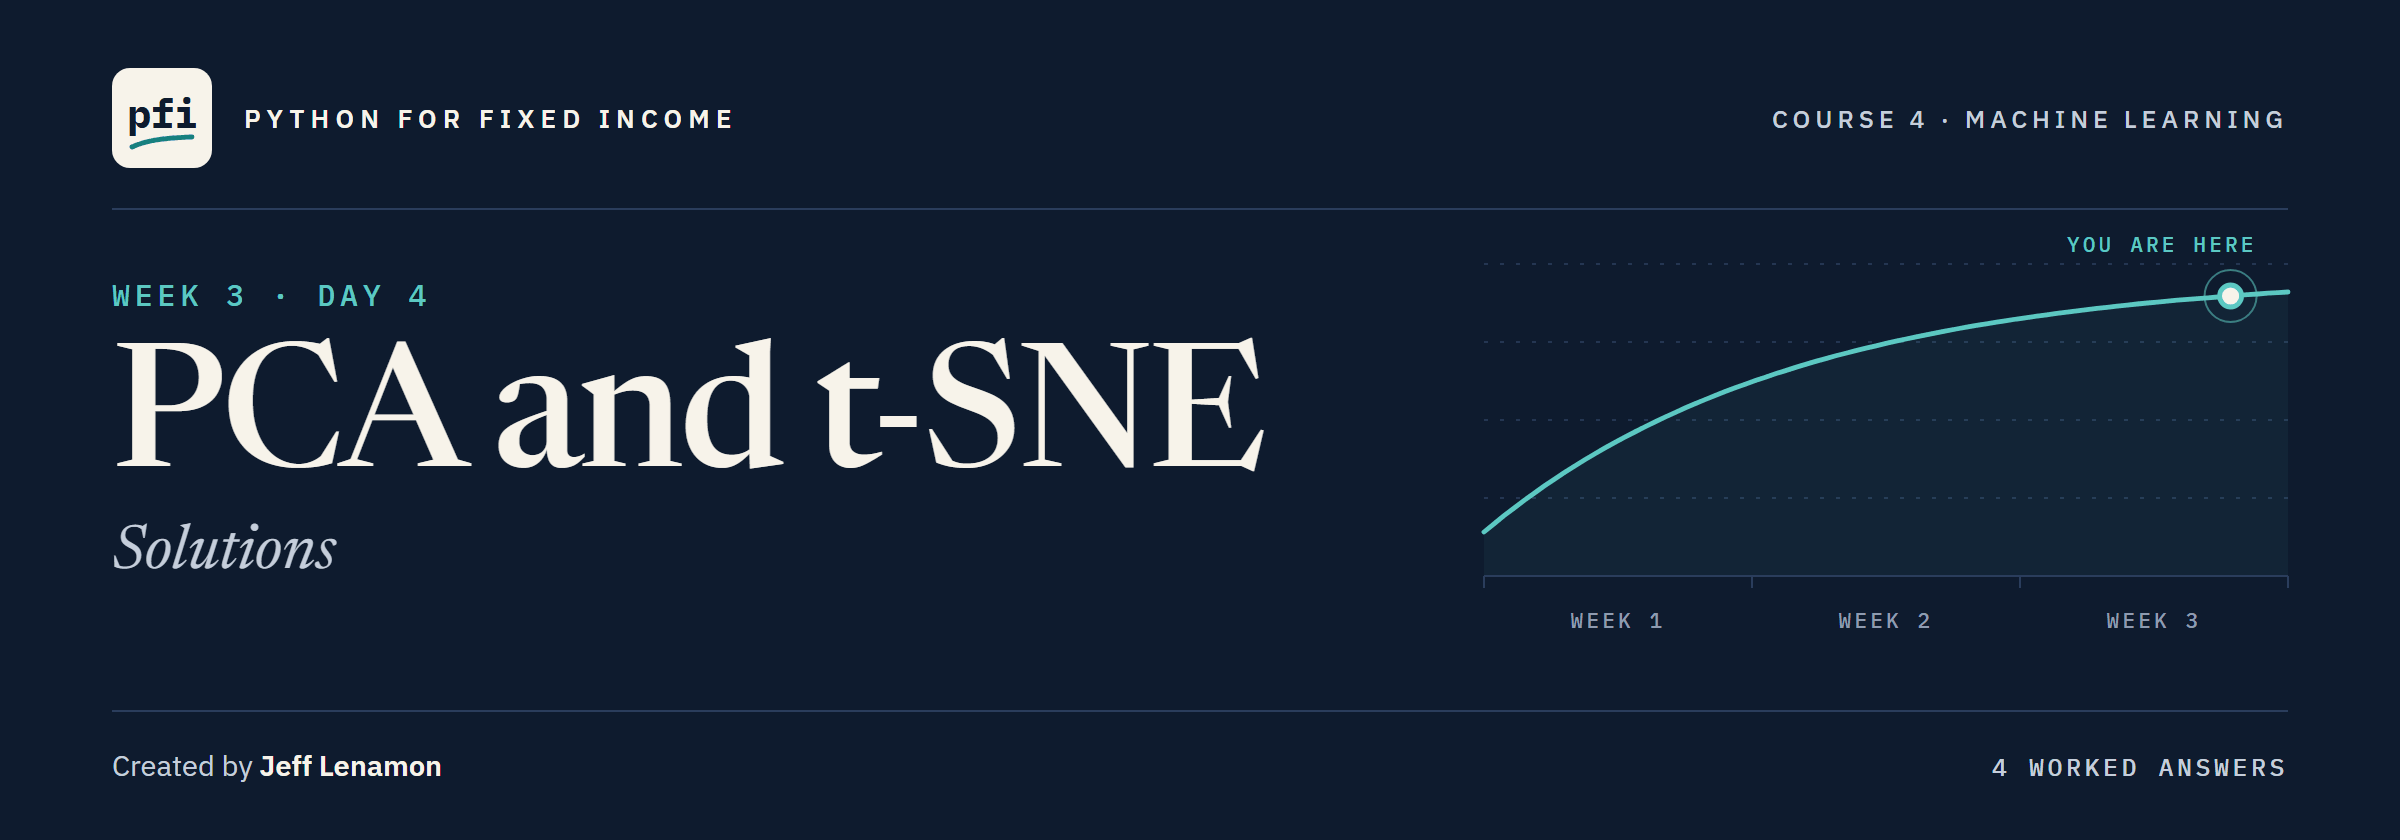

# PCA and t-SNE: Solutions

Week 3, Day 4. The full notebook with every exercise worked. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course04_machine_learning/week3/day4/14_pca_and_t_sne_solutions.ipynb)

# Problem Statement

## Business Context

Course 3 described the curve with measures you chose: the `2s10s` slope and the `2s5s10s` fly.
Today the file chooses.
A desk wants eleven Treasury yields' own history, 2015 to 2026, to say how many separate ways the curve moved and what shape each one has.
It also wants one picture of many bond columns at once.
The Treasury file is real, and everything below describes its history, never what rates will do.
The bonds are invented for this course.

## Objectives

Find the curve's shapes with PCA and read them, rebuild curves from three numbers, keep PCA inside a pipeline, scale before PCA, and draw the bonds with t-SNE.

## Data Dictionary

`treasury_par_yields.csv`, one row per market date:

1. `date`: the market date
2. `1 Mo` to `30 Yr`: eleven par yields with no gaps, in percent
3. `1.5 Month`, `2 Mo`, `4 Mo`: tenors that start partway through the file, not used

`benchmark.csv` with `ratings.csv`, one row per bond:

4. `rating` and `score`: the credit rating, and its score from 1 (AAA) to 18 (CCC)
5. `oas` (bp), `duration` (years), `coupon` (percent)

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts, and an interactive control
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# PCA, t-SNE, and two ways to judge a picture of many columns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness
from scipy.spatial.distance import pdist

# scaling, pipelines, walk-forward folds, a straight line, and Day 12's K-means
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.cluster import KMeans

# one look for every chart
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)

# Loading the Data

## Reading the Curve and the Bonds

In [3]:
# one row per market date, with the date as the index
curve = pd.read_csv(DATA + "treasury_par_yields.csv", parse_dates=["date"], index_col="date")

# the 821 bonds with each rating's score, and OAS on Day 4's log scale
bonds = pd.read_csv(DATA + "benchmark.csv")
ratings = pd.read_csv(DATA + "ratings.csv")
bonds = bonds.merge(ratings[["rating", "score"]], on="rating")
bonds["log_oas"] = np.log(bonds["oas"])

# Data Overview

## Checking the Shape and the Gaps

Q. How many dates and tenors does the file hold, and which tenors have gaps?

In [4]:
# dates by tenors, the first and last date, and the missing values in each tenor
print(curve.shape, curve.index[0].date(), curve.index[-1].date())
curve.isnull().sum()

(2940, 14) 2015-01-02 2026-10-02


1 Mo            0
1.5 Month    2532
2 Mo          949
3 Mo            0
4 Mo         1951
6 Mo            0
1 Yr            0
2 Yr            0
3 Yr            0
5 Yr            0
7 Yr            0
10 Yr           0
20 Yr           0
30 Yr           0
dtype: int64

2,940 dates and 14 tenors; three tenors miss from 949 to 2,532 dates.

## Checking the Statistical Summary

In [5]:
# keep the eleven tenors with no gaps (dropna(axis=1) drops every column that has one), then each one's mean and spread
levels = curve.dropna(axis=1)
levels.agg(["mean", "std"]).T.round(2)

,mean,std
1 Mo,2.10,1.98
3 Mo,2.16,1.96
6 Mo,2.22,1.91
1 Yr,2.24,1.79
2 Yr,2.28,1.60
3 Yr,2.34,1.48
5 Yr,2.47,1.32
7 Yr,2.64,1.24
10 Yr,2.76,1.19
20 Yr,3.13,1.17


The average rises from 2.10 percent at the 1 Mo to 3.22 at the 30 Yr, and the standard deviation falls from 1.98 to 1.06.

**Eleven clean columns in one unit, percent, with the short end the most restless.**

# Exploratory Data Analysis

## The Curve on the First Day of Each Year

Q. What shapes has the curve taken since 2015?

In [6]:
# each tenor's maturity in years
years = [1 / 12, 0.25, 0.5, 1, 2, 3, 5, 7, 10, 20, 30]

# a maturity axis on a log scale, so the short end gets room, labelled with the tenors' names
def tenor_axis(ax):
    ax.set_xscale("log")
    ax.set_xticks(years, levels.columns, rotation=90)
    ax.minorticks_off()
    ax.set_xlabel("Maturity (log scale)")

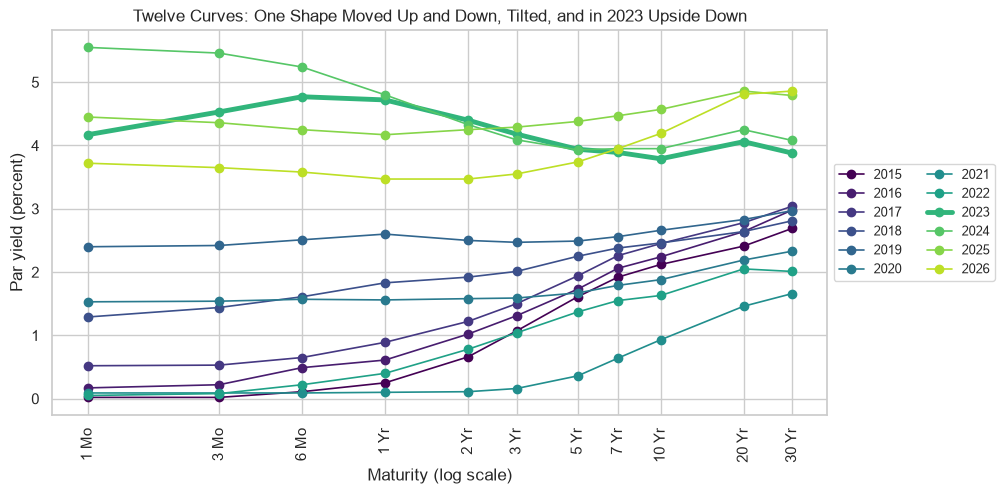

In [7]:
# the first date of each year, coloured from dark (2015) to light (2026), 2023 drawn thick
firsts = levels.groupby(levels.index.year).head(1)
# plt.cm.viridis(np.linspace(0, 0.9, 12)) takes twelve colours from the viridis colour map, dark to light, one per year
year_colours = plt.cm.viridis(np.linspace(0, 0.9, len(firsts)))
for (date, row), colour in zip(firsts.iterrows(), year_colours):
    plt.plot(years, row, marker="o", color=colour, linewidth=3.5 if date.year == 2023 else 1.2, label=date.year)
tenor_axis(plt.gca())
plt.ylabel("Par yield (percent)")
plt.legend(ncols=2, fontsize=9, loc="center left", bbox_to_anchor=(1, 0.5))  # two columns, outside on the right
plt.title("Twelve Curves: One Shape Moved Up and Down, Tilted, and in 2023 Upside Down")
plt.show()

In [8]:
# the dates on which the 10 Yr sat below the 3 Mo; then three tenors on the twelve dates
inverted = levels["10 Yr"] < levels["3 Mo"]
print(inverted.sum(), "dates, from", inverted[inverted].index[0].date(), "to", inverted[inverted].index[-1].date())
firsts[["3 Mo", "10 Yr", "30 Yr"]]

738 dates, from 2019-03-22 to 2025-10-16


,3 Mo,10 Yr,30 Yr
date,,,
2015-01-02,0.02,2.12,2.69
2016-01-04,0.22,2.24,2.98
2017-01-03,0.53,2.45,3.04
2018-01-02,1.44,2.46,2.81
2019-01-02,2.42,2.66,2.97
2020-01-02,1.54,1.88,2.33
2021-01-04,0.09,0.93,1.66
2022-01-03,0.08,1.63,2.01
2023-01-03,4.53,3.79,3.88


In 2021 the short end sat near zero, 0.09 percent at the 3 Mo.

In 2023 it was upside down: the 3 Mo at 4.53 above the 10 Yr at 3.79.

The 10 Yr sat below the 3 Mo on 738 dates between 2019-03-22 and 2025-10-16.

**Twelve curves, each mostly one curve moved up or down, with a tilt: we ask how many ways of moving there really are.**

# PCA in Two Columns

## How PCA Works

**Principal component analysis** (PCA) turns columns that move together into new columns that do not, the largest first.
Keeping the first few is **dimensionality reduction**.

Each column is first **centred** on its average.

The first **component** is the direction in which the rows spread most; the next is at right angles, and so on.

A component's weights, one per column, are its **loadings**.

A row's **score** is its centred values times the loadings, added up.

**Explained variance** is each component's share of the total.

## Fitting PCA to Two Tenors

Q. How much of the 2 Yr's and the 10 Yr's movement is one direction?

In [9]:
# the two tenors and their correlation, then PCA: PCA() keeps one component per column
two = levels[["2 Yr", "10 Yr"]]
print("Correlation:", round(two["2 Yr"].corr(two["10 Yr"]), 3))
pca_two = PCA().fit(two)
print("Averages (percent):", pca_two.mean_.round(2))
print("Share of the variance (percent):", (pca_two.explained_variance_ratio_ * 100).round(2))
print("Loadings, one row per component:")
print(pca_two.components_.round(3))

Correlation: 0.947
Averages (percent): [2.28 2.76]
Share of the variance (percent): [97.57  2.43]
Loadings, one row per component:
[[ 0.809  0.588]
 [-0.588  0.809]]


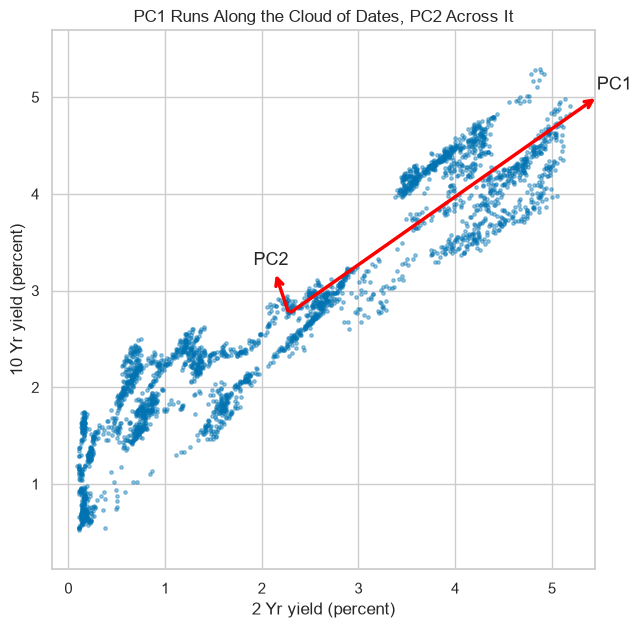

In [10]:
# the cloud of dates, and each component as an arrow from the average point, two standard deviations long
plt.figure(figsize=(7, 7))
plt.scatter(two["2 Yr"], two["10 Yr"], s=6, alpha=0.4)
for weights, variance, name in zip(pca_two.components_, pca_two.explained_variance_, ["PC1", "PC2"]):
    tip = pca_two.mean_ + weights * 2 * np.sqrt(variance)
    plt.annotate(name, xy=pca_two.mean_, xytext=tip, fontsize=13, arrowprops={"arrowstyle": "<-", "color": "red", "lw": 2.5})
plt.axis("equal")  # one percent is the same length on both axes, so right angles look right
plt.xlabel("2 Yr yield (percent)")
plt.ylabel("10 Yr yield (percent)")
plt.title("PC1 Runs Along the Cloud of Dates, PC2 Across It")
plt.show()

The tenors correlate 0.947, and PC1 carries 97.57 percent of the variance, loadings 0.809 and 0.588.

Flip a component's loadings and its scores flip too, and nothing else changes: the sign is arbitrary.

The course's rule fixes it: each component's loadings sum to a positive number.

In [11]:
# the loadings as a table, one column per component, each column flipped if its loadings sum to a negative number
def pca_loadings(pca, names):
    loadings = pd.DataFrame(pca.components_.T, index=names, columns=[f"PC{i + 1}" for i in range(pca.n_components_)])
    return loadings * np.where(loadings.sum() < 0, -1, 1)

# each component's share of the variance and the running total, in percent
def explained_table(pca):
    share = pca.explained_variance_ratio_ * 100
    return pd.DataFrame({"explained_pct": share, "cumulative_pct": share.cumsum()}, index=[f"PC{i + 1}" for i in range(len(share))])

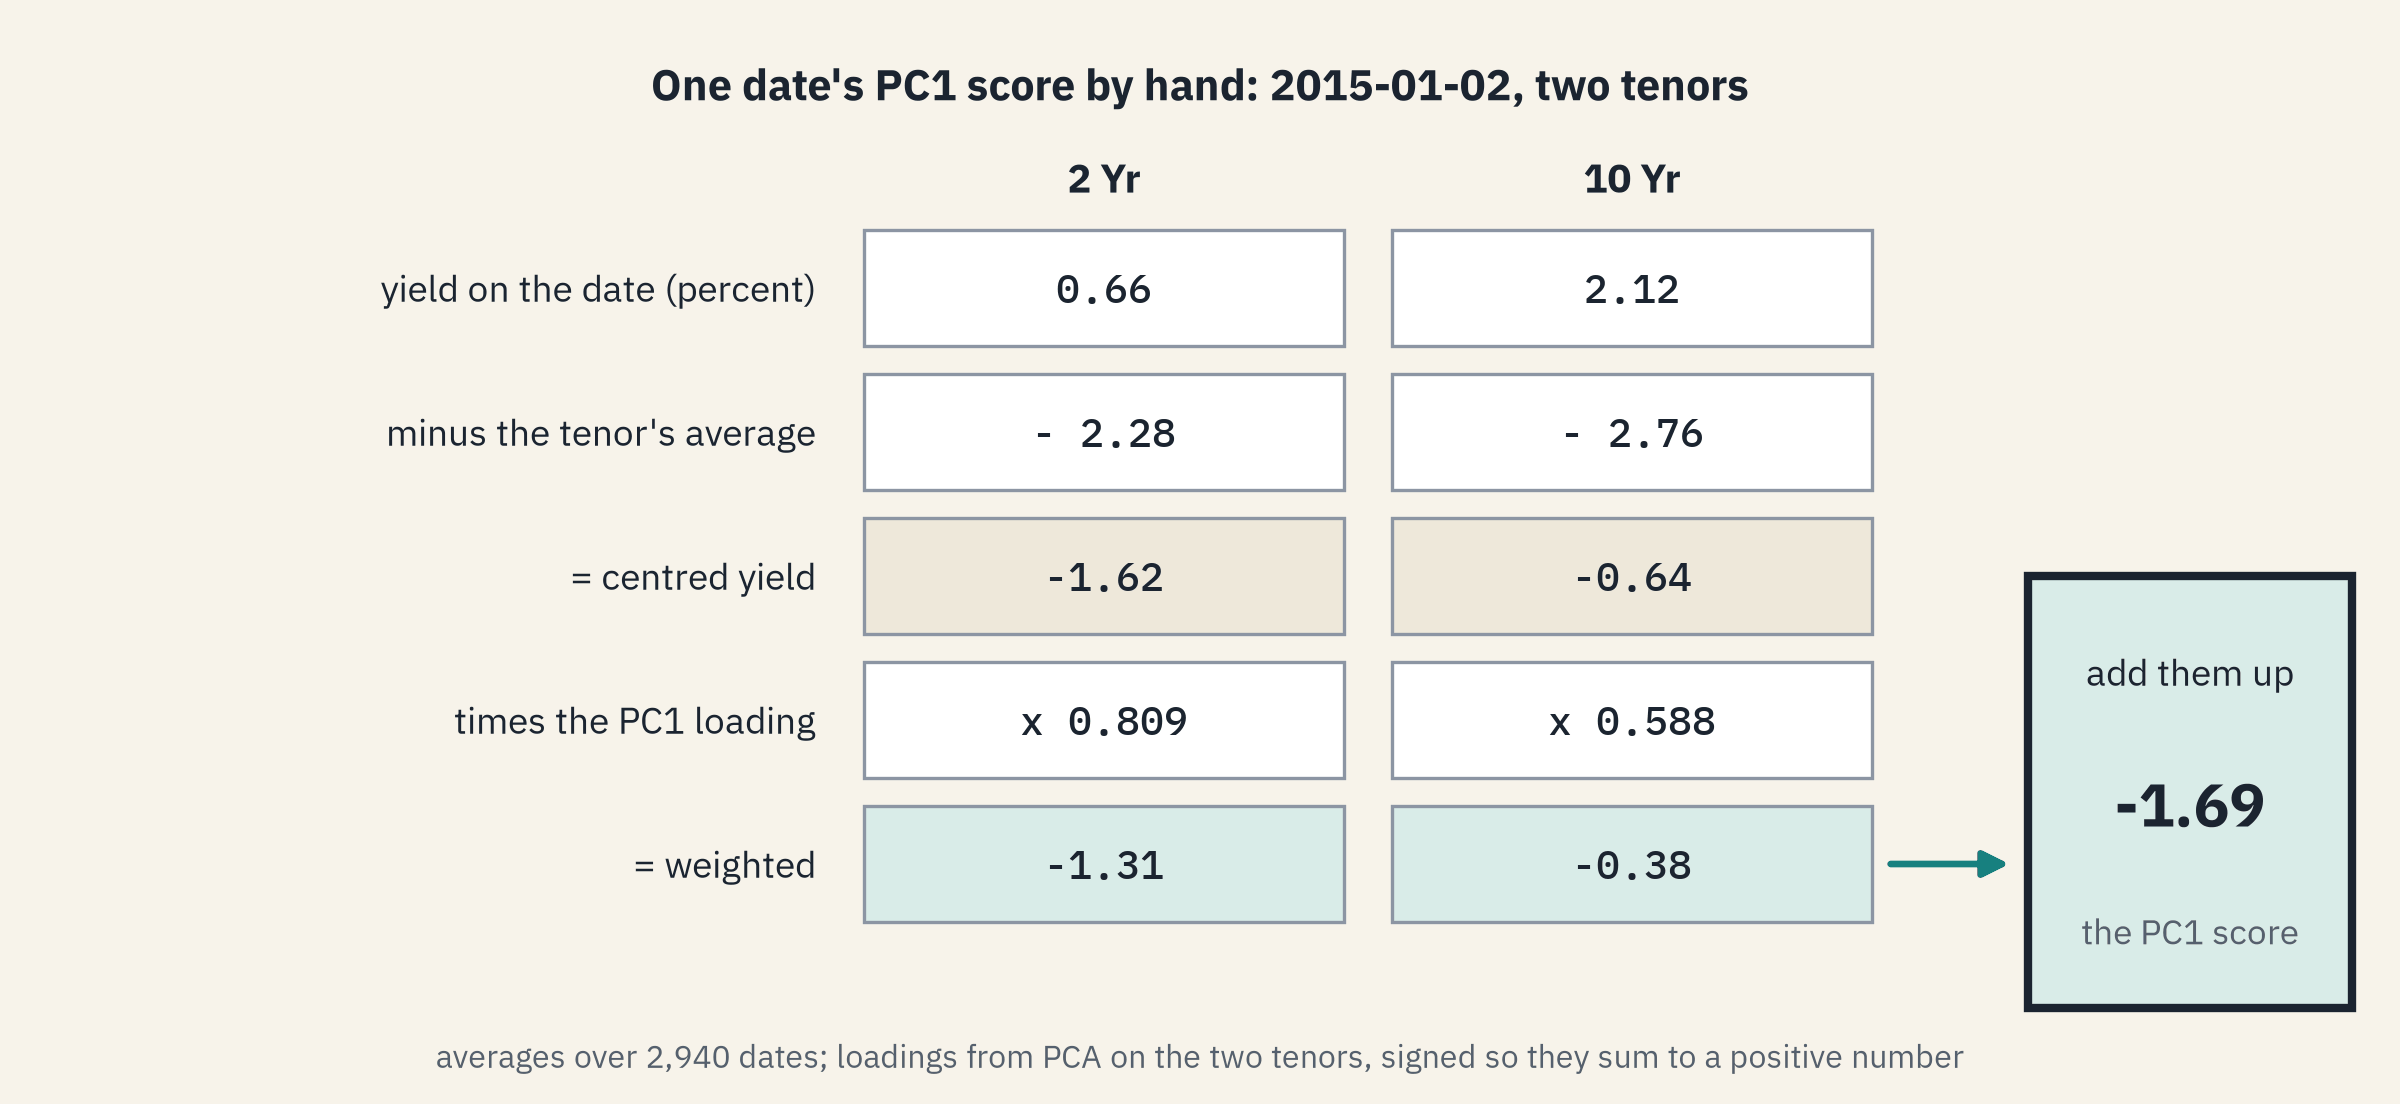

Q. What is the first date's score on PC1?

`@` multiplies each centred yield by its loading and adds them up, Course 1's matrix product.

In [12]:
# the first date's scores: its centred yields times the loadings, added up
first_scores = (two.iloc[:1] - pca_two.mean_) @ pca_loadings(pca_two, ["2 Yr", "10 Yr"])
first_scores.round(2)

,PC1,PC2
date,,
2015-01-02,-1.69,0.43


On 2015-01-02 both tenors sat below their averages, so the date's PC1 score is negative: -1.69.

**Two tenors are nearly one number. Next, all eleven.**

> STORY: PCA is usually traced to Karl Pearson's 1901 paper "On lines and planes of closest fit to systems of points in space" (Philosophical Magazine, volume 2, issue 11, pages 559 to 572). The title is the method: the line a cloud of points sits closest to.
>
> Source: the paper's Crossref record, https://api.crossref.org/works/10.1080/14786440109462720 (DOI https://doi.org/10.1080/14786440109462720).

# PCA on the Curve Levels

## Fitting PCA to Eleven Tenors

**Predict 1**

Q. Two tenors gave PC1 97.57 percent of the variance. With all eleven tenors, what share does PC1 carry?

In [13]:
# PCA on the eleven tenors over every date, and each component's share
pca = PCA().fit(levels)
explained = explained_table(pca)
explained.round(2)

,explained_pct,cumulative_pct
PC1,95.62,95.62
PC2,3.38,99.00
PC3,0.86,99.86
PC4,0.08,99.94
PC5,0.03,99.96
PC6,0.02,99.98
PC7,0.01,99.99
PC8,0.00,100.00
PC9,0.00,100.00
PC10,0.00,100.00


PC1 carries 95.62 percent, PC2 3.38 and PC3 0.86: three components carry 99.86 percent of eleven tenors' variance.

## The Scree Plot

A **scree plot** draws each component's share as a bar, falling away like loose stones below a cliff.

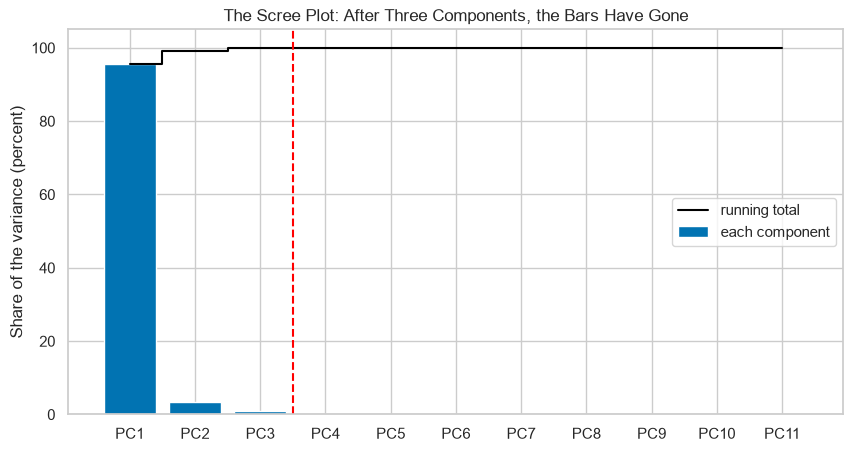

In [14]:
# each component's share as a bar, the running total as a step line, a dashed line after the third
plt.bar(explained.index, explained["explained_pct"], label="each component")
plt.step(explained.index, explained["cumulative_pct"], where="mid", color="black", label="running total")
plt.axvline(2.5, color="red", linestyle="--")
plt.ylabel("Share of the variance (percent)")
plt.legend(loc="center right")
plt.title("The Scree Plot: After Three Components, the Bars Have Gone")
plt.show()

## Reading the Loadings

Q. What shape does each of the first three components draw across the curve?

         PC1    PC2    PC3
1 Mo   0.383 -0.371  0.475
3 Mo   0.384 -0.345  0.213
6 Mo   0.374 -0.281 -0.062
1 Yr   0.352 -0.168 -0.297
2 Yr   0.316  0.029 -0.408
3 Yr   0.290  0.143 -0.386
5 Yr   0.257  0.268 -0.211
7 Yr   0.238  0.323 -0.055
10 Yr  0.225  0.361  0.123
20 Yr  0.219  0.383  0.293
30 Yr  0.193  0.402  0.417


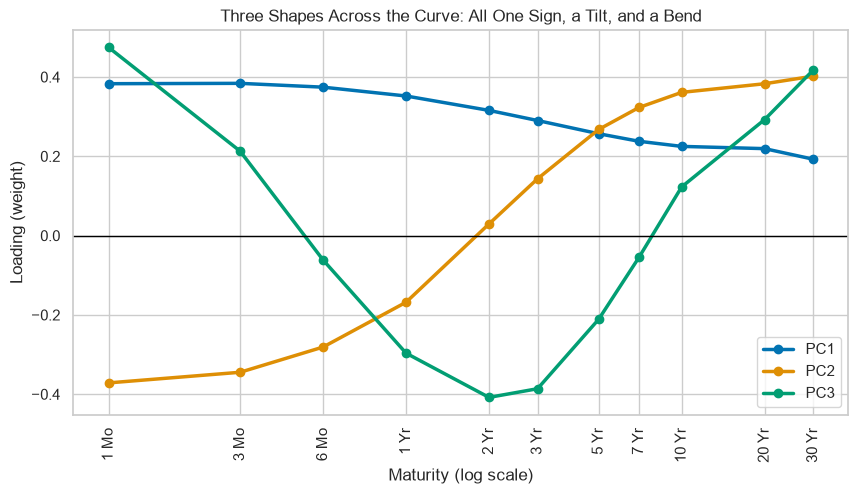

In [15]:
# the loadings of the first three components, one row per tenor
loadings = pca_loadings(pca, list(levels.columns))[["PC1", "PC2", "PC3"]]
print(loadings.round(3))

# each component's loadings across maturity, zero marked
for name in ["PC1", "PC2", "PC3"]:
    plt.plot(years, loadings[name], marker="o", linewidth=2.5, label=name)
plt.axhline(0, color="black", linewidth=1)
tenor_axis(plt.gca())
plt.ylabel("Loading (weight)")
plt.legend()
plt.title("Three Shapes Across the Curve: All One Sign, a Tilt, and a Bend")
plt.show()

### Interpretation of the Loadings

PC1 is positive on every tenor, 0.193 to 0.384: every yield moves one way.

Its name is **level**.

PC2 is negative to the 1 Yr and positive from the 2 Yr: one end against the other.

Its name is **slope**.

PC3 is positive at both ends and negative from the 6 Mo to the 7 Yr: belly against wings.

Its name is **curvature**.

These name shapes of weights in this file's history, not what moves rates.

## Each Shape as a Curve

Q. How far does each shape move the curve?

         PC1    PC2   PC3
1 Mo   552.0 -112.0  79.0
2 Yr   455.0    9.0 -68.0
10 Yr  324.0  109.0  21.0
30 Yr  278.0  121.0  70.0


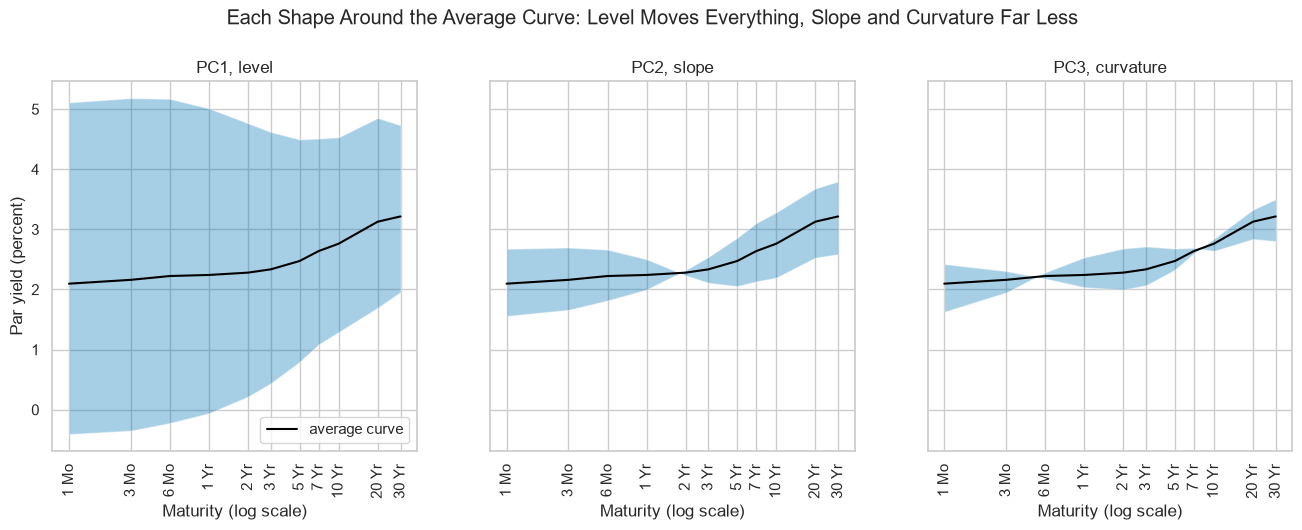

In [16]:
# every date's first three scores, their 5th and 95th percentiles, and how far each shape moves four tenors between them, in bp
scores = (levels - pca.mean_) @ loadings
low, high = scores.quantile(0.05), scores.quantile(0.95)
widths = (high - low) * loadings * 100
print(widths.loc[["1 Mo", "2 Yr", "10 Yr", "30 Yr"]].round(0))

# one panel per component: the average curve, and the band between its curves at the 5th and 95th percentile score
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
for ax, name, shape in zip(axes, ["PC1", "PC2", "PC3"], ["level", "slope", "curvature"]):
    ax.fill_between(years, pca.mean_ + low[name] * loadings[name], pca.mean_ + high[name] * loadings[name], alpha=0.35)
    ax.plot(years, pca.mean_, color="black", label="average curve")
    ax.set_title(f"{name}, {shape}")
    tenor_axis(ax)
axes[0].set_ylabel("Par yield (percent)")
axes[0].legend(loc="lower right")
fig.suptitle("Each Shape Around the Average Curve: Level Moves Everything, Slope and Curvature Far Less", y=1.03)
plt.show()

Level moves every tenor one way: the 1 Mo by 552 bp, the 30 Yr by 278.

Slope moves the ends apart, the 1 Mo by -112 bp as the 30 Yr moves 121, and curvature the 2 Yr by -68 against both wings.

The level band dips below zero from the 1 Mo to the 1 Yr, where no yield in the file went: each band is one shape alone.

**Next: how much of a curve three numbers keep.**

# Three Numbers a Day

## Rebuilding a Curve From Its Scores

Q. How close does a curve rebuilt from its first k scores come to the real one?

`inverse_transform` turns scores back into yields: the average curve plus each score times its loadings.

In [17]:
# rebuild every date from its first k scores, and the average miss over every date and tenor, in bp
for k in range(1, 5):
    pca_k = PCA(n_components=k).fit(levels)
    rebuilt = pca_k.inverse_transform(pca_k.transform(levels))
    print(k, "components: average miss", round(np.abs(levels - rebuilt).mean().mean() * 100, 2), "bp")

1 components: average miss 25.84 bp
2 components: average miss 10.6 bp
3 components: average miss 4.35 bp
4 components: average miss 2.85 bp


In [18]:
# one date's actual curve as dots, and the curve rebuilt from its first k scores as a line
def draw_rebuilt(ax, date, k):
    pca_k = PCA(n_components=k).fit(levels)
    rebuilt = pca_k.inverse_transform(pca_k.transform(levels.loc[[date]]))[0]
    miss = np.abs(levels.loc[date] - rebuilt).mean() * 100
    ax.plot(years, rebuilt, color="red", linewidth=2.5, label=f"rebuilt from {k}")
    ax.scatter(years, levels.loc[date], color="black", zorder=3, label="actual")
    ax.set_title(f"{date}, {k} kept: average miss {miss:.1f} bp")
    tenor_axis(ax)

# your turn: pick a date and how many components to keep
# the dates: the first, the lowest yields, the 10 Yr furthest below the 3 Mo, the last
dates = ["2015-01-02", "2020-08-04", "2023-06-01", "2026-10-02"]

def rebuild(date="2023-06-01", k=1):
    fig, ax = plt.subplots(figsize=(9, 5))
    draw_rebuilt(ax, date, k)
    ax.set_ylabel("Par yield (percent)")
    ax.legend()
    plt.show()

interact(rebuild, date=dates, k=(1, 4, 1));

interactive(children=(Dropdown(description='date', index=2, options=('2015-01-02', '2020-08-04', '2023-06-01',…

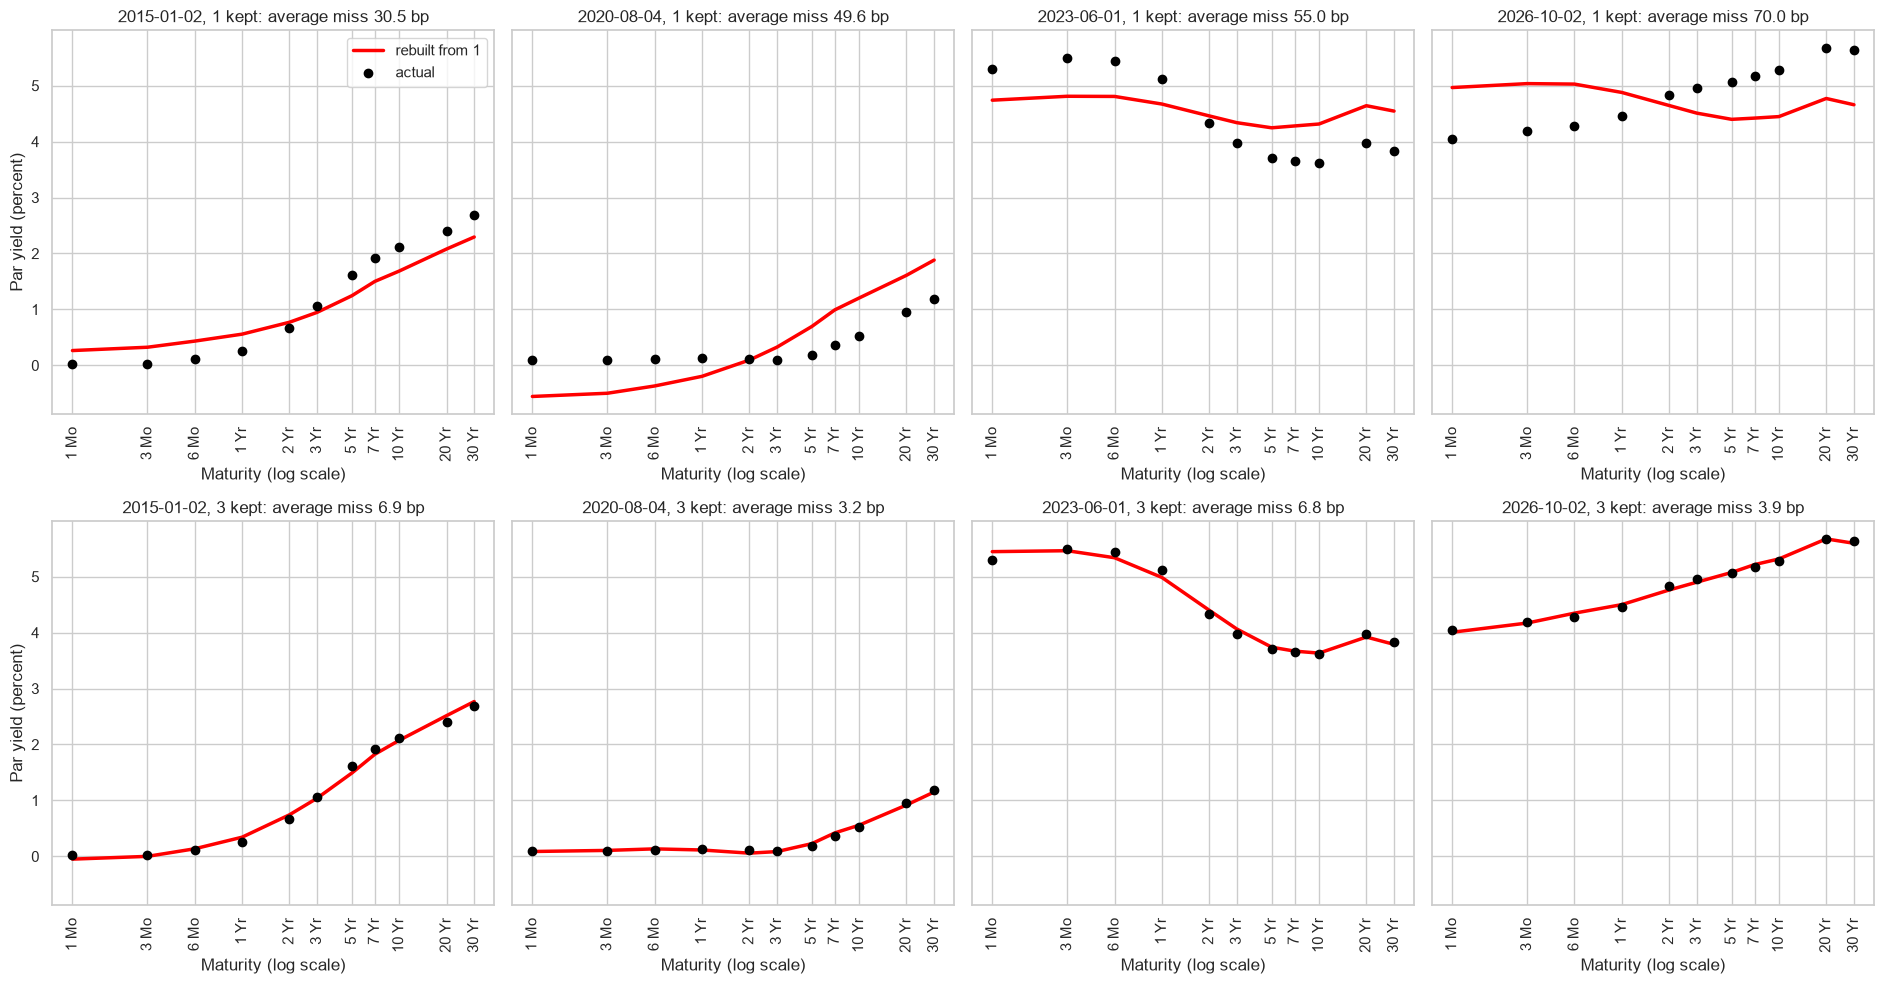

In [19]:
# the four dates with one component kept (top) and three (bottom), drawn as a still picture (the controls do not run on GitHub)
fig, axes = plt.subplots(2, 4, figsize=(19, 10), sharey=True)
for row, k in zip(axes, [1, 3]):
    for ax, date in zip(row, dates):
        draw_rebuilt(ax, date, k)
axes[0, 0].legend()
axes[0, 0].set_ylabel("Par yield (percent)")
axes[1, 0].set_ylabel("Par yield (percent)")
fig.tight_layout()
plt.show()

Level alone gets the height and misses every tilt: 55.0 bp on 2023-06-01.

Three scores rebuild that date to 6.8 bp, and the whole file to 4.35 bp on average.

**Three numbers a day keep the curve to a few bp, so we can watch its whole history in two of them.**

## The Curve's Path, 2015 to 2026

Q. Where has the curve travelled in level and slope?

In [20]:
# the dates of the lowest and highest level and slope scores, with four tenors on each
extremes = [scores["PC1"].idxmin(), scores["PC1"].idxmax(), scores["PC2"].idxmin(), scores["PC2"].idxmax()]
print("Level score with the average of the eleven yields:", round(scores["PC1"].corr(levels.mean(axis=1)), 4))
levels.loc[extremes, ["3 Mo", "2 Yr", "10 Yr", "30 Yr"]].assign(level=scores["PC1"], slope=scores["PC2"]).round(2)

Level score with the average of the eleven yields: 0.9991


,3 Mo,2 Yr,10 Yr,30 Yr,level,slope
date,,,,,,
2020-08-04,0.09,0.11,0.52,1.19,-6.93,-1.78
2023-10-19,5.60,5.14,4.98,5.11,9.24,0.33
2023-05-04,5.26,3.75,3.37,3.73,6.02,-2.29
2026-09-30,4.20,4.88,5.29,5.64,7.58,2.45


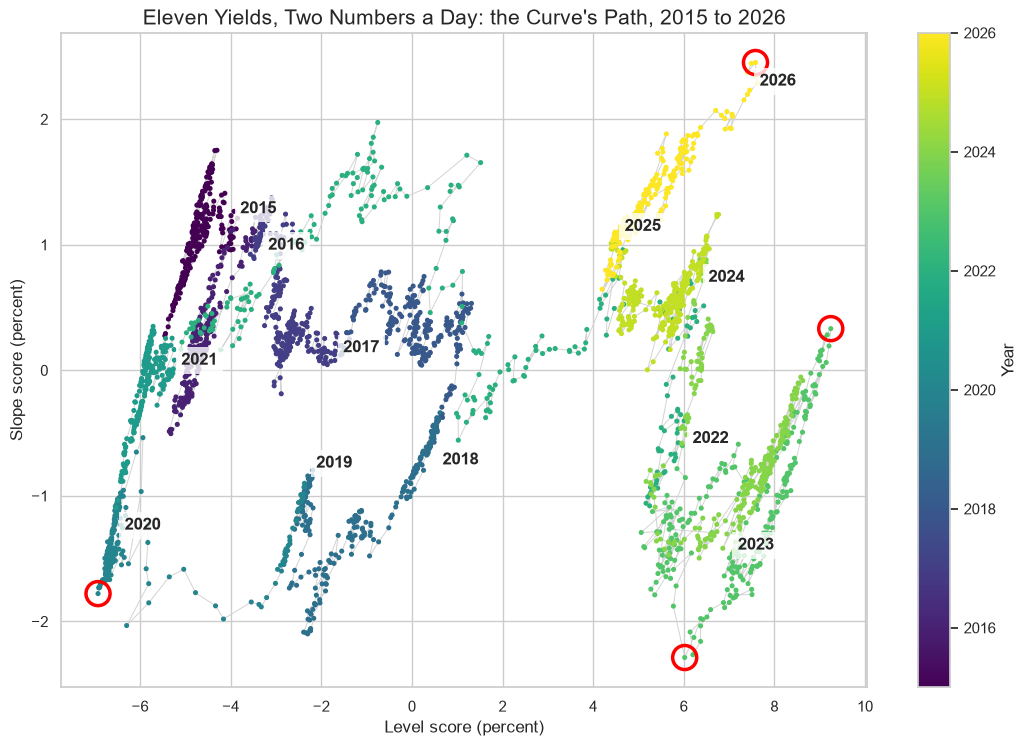

In [21]:
# the showpiece: level against slope, one thin line through the dates in order, dots coloured by year
fig, ax = plt.subplots(figsize=(13, 8.5))
ax.plot(scores["PC1"], scores["PC2"], color="lightgray", linewidth=0.7, zorder=1)
dots = ax.scatter(scores["PC1"], scores["PC2"], c=scores.index.year, cmap="viridis", s=7, zorder=2)
fig.colorbar(dots, label="Year")
# each year's last date labelled (odd years above, even years below), the four extremes ringed
for date, row in scores.groupby(scores.index.year).tail(1).iterrows():
    ax.annotate(date.year, (row["PC1"], row["PC2"]), xytext=(6, 6 if date.year % 2 else -16), textcoords="offset points",
                weight="bold", zorder=4, bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.8})  # a white patch behind the year
ax.scatter(scores.loc[extremes, "PC1"], scores.loc[extremes, "PC2"], s=300, facecolor="none", edgecolor="red", linewidth=2.5, zorder=3)
ax.set_xlabel("Level score (percent)")
ax.set_ylabel("Slope score (percent)")
ax.set_title("Eleven Yields, Two Numbers a Day: the Curve's Path, 2015 to 2026", fontsize=15)
plt.show()

The level score follows the average yield, correlation 0.9991; the slope score is the tilt left after level, negative when the long end sits below where level alone puts it.

The path runs left to the lowest level on 2020-08-04, then right to the highest on 2023-10-19.

Slope is lowest on 2023-05-04, the 10 Yr at 3.37 under the 3 Mo at 5.26, and highest on 2026-09-30.

This is the file's history: every number moves a little if the file gains a date.

**Over the span, three shapes carry the curve. A desk asks about days, so we repeat it on daily changes.**

# PCA on Daily Changes

## Daily Changes in bp

From here we keep the eight tenors from the 1 Yr out, where Course 3's slopes and flies live.

(2939, 8)


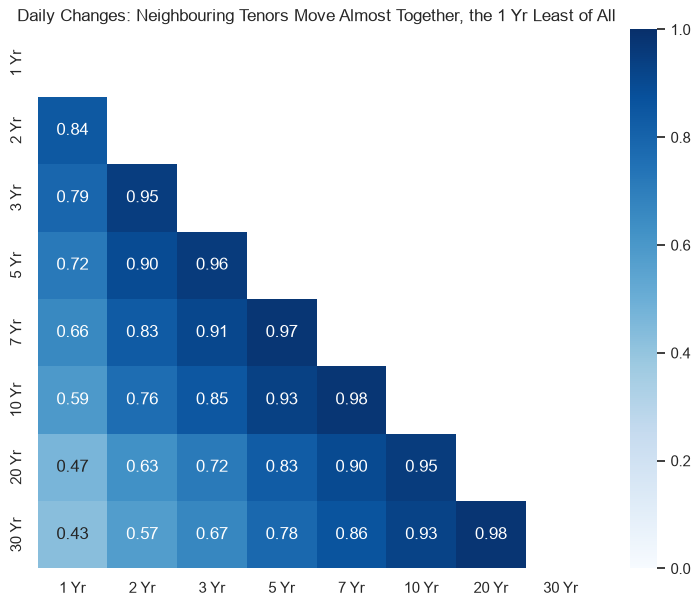

In [22]:
# each day's change in bp for the 1 Yr to the 30 Yr; the first date has no day before it
tenors = ["1 Yr", "2 Yr", "3 Yr", "5 Yr", "7 Yr", "10 Yr", "20 Yr", "30 Yr"]
changes = levels[tenors].diff().dropna() * 100
print(changes.shape)

# how closely each pair of tenors' daily changes move together; np.triu hides the upper half and the diagonal
plt.figure(figsize=(9, 7))
sns.heatmap(changes.corr(), mask=np.triu(np.ones((8, 8), dtype=bool)), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.grid(False)
plt.title("Daily Changes: Neighbouring Tenors Move Almost Together, the 1 Yr Least of All")
plt.show()

The 20 Yr and 30 Yr changes correlate 0.98; the 1 Yr and 30 Yr, the palest cell, 0.43.

## Fitting PCA to the Changes

In [23]:
# PCA on the daily changes, and each component's share
pca_changes = PCA().fit(changes)
explained_table(pca_changes).round(2)

,explained_pct,cumulative_pct
PC1,85.04,85.04
PC2,11.02,96.06
PC3,2.11,98.17
PC4,0.83,99.00
PC5,0.42,99.42
PC6,0.22,99.64
PC7,0.21,99.85
PC8,0.15,100.00


PC1 carries 85.04 percent of the daily variance, three components 98.17: days are noisier than levels.

## The Third Shape of a Day

**Predict 2**

Q. On the levels, PC3 was curvature. Sketch PC3 of the daily changes across the eight tenors.

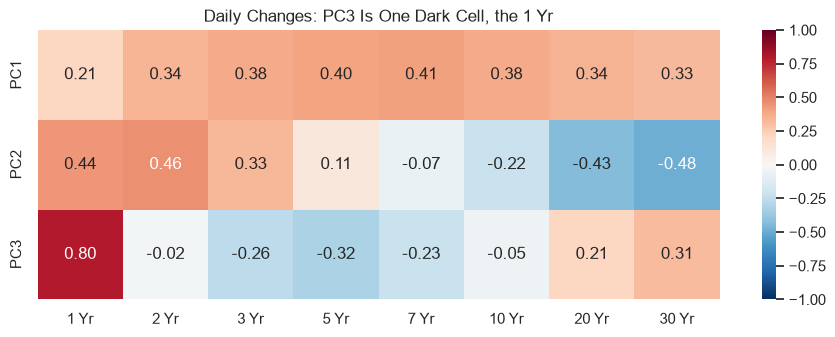

In [24]:
# the first three components' loadings, one row each, red above zero and blue below
change_loadings = pca_loadings(pca_changes, tenors)[["PC1", "PC2", "PC3"]]
plt.figure(figsize=(11, 3.5))
sns.heatmap(change_loadings.T, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Daily Changes: PC3 Is One Dark Cell, the 1 Yr")
plt.show()

PC1 is positive everywhere and largest at the 7 Yr: level again.

PC2 is positive from the 1 Yr to the 5 Yr and negative beyond: slope again, short end up.

PC3 is the 1 Yr on its own, 0.80, with no other tenor beyond 0.32 either way.

## Taking Out the 1 Yr

Q. Without the 1 Yr, what does the third component of a day look like?

In [25]:
# the same PCA on the seven tenors from the 2 Yr out: the third component's loadings
seven = tenors[1:]
pca_seven = PCA().fit(changes[seven])
pca_loadings(pca_seven, seven)["PC3"].round(3)

2 Yr     0.657
3 Yr    -0.059
5 Yr    -0.401
7 Yr    -0.410
10 Yr   -0.194
20 Yr    0.224
30 Yr    0.386
Name: PC3, dtype: float64

Positive at the 2 Yr and from the 20 Yr out, negative through the belly, -0.410 at the 7 Yr: curvature is back.

## Scores Against Course 3's Measures

Q. How close is each score to a measure the desk already uses?

In [26]:
# each day's first three scores, beside the average change, Course 3's 2s10s and its 2s5s10s fly, all in bp
change_scores = (changes - pca_changes.mean_) @ change_loadings
two_tens = changes["10 Yr"] - changes["2 Yr"]
fly = 2 * changes["5 Yr"] - changes["2 Yr"] - changes["10 Yr"]
print("PC1 with the average change:", round(change_scores["PC1"].corr(changes.mean(axis=1)), 4))
print("PC2 with the change in 2s10s:", round(change_scores["PC2"].corr(two_tens), 4))
print("PC3 with the change in the fly:", round(change_scores["PC3"].corr(fly), 4))

PC1 with the average change: 0.9995
PC2 with the change in 2s10s: -0.9174
PC3 with the change in the fly: -0.4509


PC1 is the average move, 0.9995, and PC2 moves against 2s10s, -0.9174, because the sign rule points it short end up.

PC3 shares far less with the fly, -0.4509: the fly is a shape someone chose, and PC3 leans on the 1 Yr.

**A name belongs to the loadings of a given set of columns. Next, PCA as a step that builds features.**

# PCA Inside a Pipeline

## A Fit on the Whole File Uses Later Rows

Q. Do the loadings stay put as the file grows?

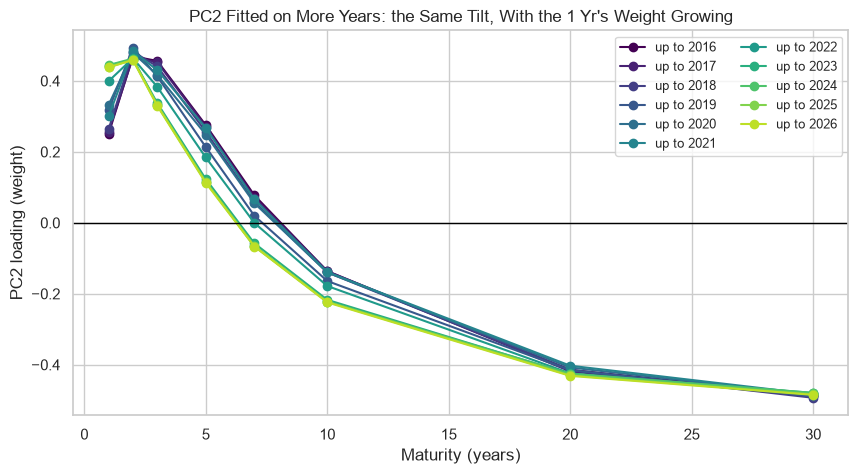

The 1 Yr's PC2 weight: {2016: 0.251, 2017: 0.257, 2018: 0.264, 2019: 0.318, 2020: 0.332, 2021: 0.3, 2022: 0.399, 2023: 0.443, 2024: 0.444, 2025: 0.438, 2026: 0.438}


In [27]:
# PC2's loadings from PCA fitted on the changes up to the end of each year, 2016 to 2026, one line per fit
drift = pd.DataFrame({year: pca_loadings(PCA(n_components=3).fit(changes.loc[:str(year)]), tenors)["PC2"]
                      for year in range(2016, 2027)})
for year, colour in zip(drift.columns, plt.cm.viridis(np.linspace(0, 0.9, len(drift.columns)))):
    plt.plot(years[3:], drift[year], marker="o", color=colour, label=f"up to {year}")
plt.axhline(0, color="black", linewidth=1)
plt.xlabel("Maturity (years)")
plt.ylabel("PC2 loading (weight)")
plt.legend(ncols=2, fontsize=9)
plt.title("PC2 Fitted on More Years: the Same Tilt, With the 1 Yr's Weight Growing")
plt.show()
print("The 1 Yr's PC2 weight:", drift.loc["1 Yr"].round(3).to_dict())

The tilt keeps its shape, and the 1 Yr's weight grows from 0.251 to 0.438.

So a whole-file PCA gives every date loadings that later dates helped choose: Course 3's lookahead, through a fitted step.

## The No-Lookahead Check

Course 3's check: compute on the whole file and on the file with every later row deleted, and compare.

In [28]:
# scores of the dates up to the cut, from a PCA fitted on those dates only
def scores_to(rows, cut):
    window = rows.loc[:cut]
    pca_cut = PCA(n_components=3).fit(window)
    return (window - pca_cut.mean_) @ pca_loadings(pca_cut, tenors)

cut = "2021-01-04"
print("Fitted up to the cut, the same scores with later rows deleted:", scores_to(changes, cut).equals(scores_to(changes.loc[:cut], cut)))

# the same dates scored by a PCA fitted on the whole file: the largest gap from the fit up to the cut, in bp
whole = PCA(n_components=3).fit(changes)
whole_scores = (changes.loc[:cut] - whole.mean_) @ pca_loadings(whole, tenors)
print("Fitted on the whole file, the largest gap in bp:", (whole_scores - scores_to(changes, cut)).abs().max().round(2).to_dict())

Fitted up to the cut, the same scores with later rows deleted: True
Fitted on the whole file, the largest gap in bp: {'PC1': 4.08, 'PC2': 9.65, 'PC3': 4.03}


Fitted up to the cut, the scores use only the past.

Fitted on the whole file, the same dates' scores move by up to 9.65 bp on PC2.

## Three Components Then a Line, Walk-Forward

The task: a day's 30 Yr change, given the same day's changes in the seven shorter tenors.

It describes how the long end moved with the rest that day, and says nothing about any later day.

A `Pipeline` (Day 5) refits PCA in every fold, on its training dates only.

In [29]:
# features: the seven shorter tenors' changes; target: the same day's 30 Yr change, in bp
X = changes[tenors[:-1]]
y = changes["30 Yr"]

# Day 11's walk-forward folds: 19 test windows of 126 dates, each after every date it is fitted on
wf = TimeSeriesSplit(n_splits=19, test_size=126)

In [30]:
# three components then a line, as one pipeline
pca_line = Pipeline([("pca", PCA(n_components=3)), ("line", LinearRegression())])

# fold 1 by hand: next() takes the first fold the splitter hands out, and the pipeline is fitted on its training dates
fit_rows = next(wf.split(X))[0]
pca_line.fit(X.iloc[fit_rows], y.iloc[fit_rows])

# are the PCA step's averages those of fold 1's training dates, or of the whole file?
print("Fold 1 trains on", len(fit_rows), "dates, up to", X.index[fit_rows[-1]].date())
print("Averages match fold 1's training dates:", np.allclose(pca_line["pca"].mean_, X.iloc[fit_rows].mean()))
print("Averages match the whole file:", np.allclose(pca_line["pca"].mean_, X.mean()))

Fold 1 trains on 545 dates, up to 2017-03-08
Averages match fold 1's training dates: True
Averages match the whole file: False


In [31]:
# MAE in bp in each fold: three components then a line, against the line on all seven tenors
pca_mae = -cross_val_score(pca_line, X, y, cv=wf, scoring="neg_mean_absolute_error")
line_mae = -cross_val_score(LinearRegression(), X, y, cv=wf, scoring="neg_mean_absolute_error")
print("Three components then a line:", round(pca_mae.mean(), 2), "bp")
print("The line on all seven tenors:", round(line_mae.mean(), 2), "bp")
print("Folds where the pipeline misses by more:", (pca_mae > line_mae).sum(), "of 19")

Three components then a line: 0.85 bp
The line on all seven tenors: 0.72 bp
Folds where the pipeline misses by more: 19 of 19


`neg_mean_absolute_error` hands back minus the MAE (Day 11), so a minus sign turns it back into bp.

Fitted on fold 1, the PCA step's averages are its 545 training dates' own: no later date went in, and each fold refits it the same way.

Three components miss the same day's 30 Yr change by 0.85 bp on average, the seven tenors themselves by 0.72, and the line wins every fold.

## How Many Components to Keep

**Predict 3**

Q. Keep all seven components instead of three. Where does the walk-forward MAE land?

{1: 2.04, 2: 1.01, 3: 0.85, 4: 0.75, 5: 0.72, 6: 0.72, 7: 0.72}


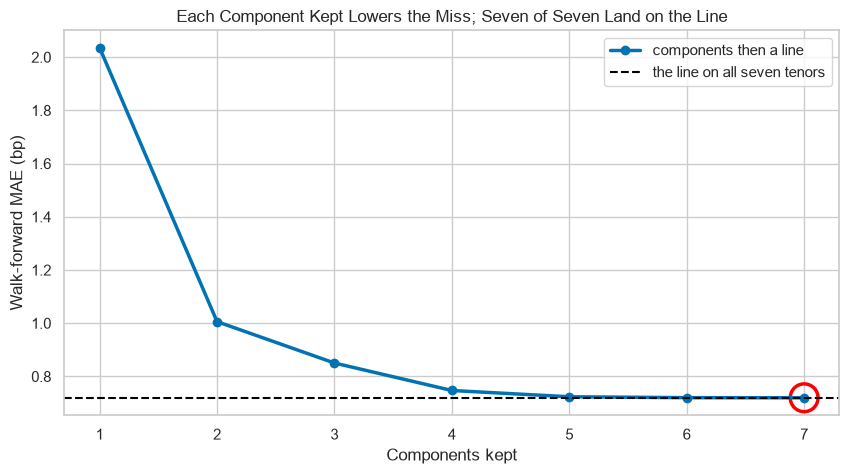

In [32]:
# walk-forward MAE in bp with 1 to 7 components kept
mae_by_k = {}
for k in range(1, 8):
    pipe = Pipeline([("pca", PCA(n_components=k)), ("line", LinearRegression())])
    mae_by_k[k] = -cross_val_score(pipe, X, y, cv=wf, scoring="neg_mean_absolute_error").mean()
mae_by_k = pd.Series(mae_by_k)
print(mae_by_k.round(2).to_dict())

# MAE against the components kept, the line on all seven tenors dashed, seven components ringed
plt.plot(mae_by_k.index, mae_by_k, marker="o", linewidth=2.5, label="components then a line")
plt.axhline(line_mae.mean(), color="black", linestyle="--", label="the line on all seven tenors")
plt.scatter(7, mae_by_k[7], s=400, facecolor="none", edgecolor="red", linewidth=2.5)
plt.xlabel("Components kept")
plt.ylabel("Walk-forward MAE (bp)")
plt.legend()
plt.title("Each Component Kept Lowers the Miss; Seven of Seven Land on the Line")
plt.show()

In [33]:
# the largest gap between seven components then a line and the line itself, over every test date, in bp
gaps = []
for train, test in wf.split(X):
    seven_fit = Pipeline([("pca", PCA(n_components=7)), ("line", LinearRegression())]).fit(X.iloc[train], y.iloc[train])
    line_fit = LinearRegression().fit(X.iloc[train], y.iloc[train])
    gaps.append(np.abs(seven_fit.predict(X.iloc[test]) - line_fit.predict(X.iloc[test])).max())
print(f"Largest gap: {max(gaps):.0e} bp")  # .0e writes the number as a power of ten: 1e-3 is 0.001

Largest gap: 4e-14 bp


Seven components are the seven tenors on rotated axes, so the line on them gives the same fitted value on every test day, to rounding.

**PCA compresses: it loses detail only when components are dropped, and it is fitted on the training rows only. Now columns in different units.**

# Scaling Before PCA

## Four Columns in Four Units, Raw Against Scaled

Q. The four bond columns Day 12 clustered each have their own unit. What does PCA make of them as they are, and scaled?

In [34]:
# the four columns, and each one's standard deviation: log OAS, years, percent, notches
features = ["log_oas", "duration", "coupon", "score"]
print("Standard deviations:", bonds[features].std().round(3).to_dict())

# PCA on the columns as they are, and on the columns scaled as Day 12 scaled them; their first two loadings and the shares
X_bonds = pd.DataFrame(StandardScaler().fit_transform(bonds[features]), columns=features)
pca_raw = PCA().fit(bonds[features])
pca_scaled = PCA().fit(X_bonds)
raw_load = pca_loadings(pca_raw, features)[["PC1", "PC2"]]
scaled_load = pca_loadings(pca_scaled, features)[["PC1", "PC2"]]
print(raw_load.round(3))
print(scaled_load.round(3))
print("Raw shares:", explained_table(pca_raw)["explained_pct"].round(2).tolist())
print("Scaled shares:", explained_table(pca_scaled)["explained_pct"].round(2).tolist())

Standard deviations: {'log_oas': 0.736, 'duration': 3.253, 'coupon': 1.655, 'score': 3.433}
            PC1    PC2
log_oas   0.179  0.063
duration -0.252  0.963
coupon    0.317  0.174
score     0.897  0.197
            PC1    PC2
log_oas   0.602 -0.008
duration -0.005  0.981
coupon    0.542  0.151
score     0.586 -0.123
Raw shares: [54.46, 40.72, 4.62, 0.2]
Scaled shares: [64.96, 25.7, 7.94, 1.41]


Raw, PC1 is mostly the rating score, 0.897, and PC2 mostly duration, 0.963: the two columns with the largest standard deviations.

Scaled, PC1 is log OAS, coupon and score together, and PC2 is duration alone, 0.981.

A **biplot** draws the rows on their first two scores and each column's loadings as an arrow.

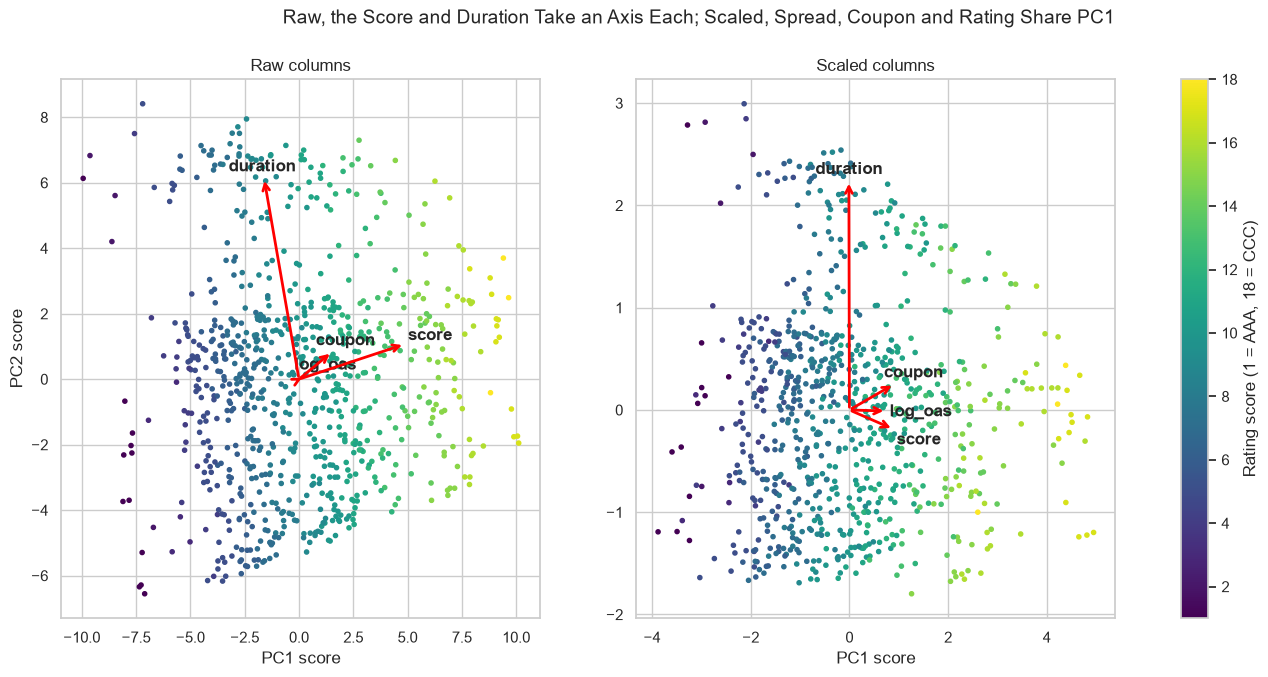

In [35]:
# each bond's first two scores, raw and scaled
raw_points = (bonds[features] - pca_raw.mean_) @ raw_load
scaled_points = (X_bonds - pca_scaled.mean_) @ scaled_load

# two biplots: bonds coloured by rating score, each column's arrow stretched to most of the panel's width, so it shows
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, points, load, name in [(axes[0], raw_points, raw_load, "Raw columns"), (axes[1], scaled_points, scaled_load, "Scaled columns")]:
    dots = ax.scatter(points["PC1"], points["PC2"], c=bonds["score"], cmap="viridis", s=9)
    stretch = 0.8 * min(points["PC1"].max(), points["PC2"].max())
    for column in features:
        # each name centred on its arrow's tip (ha= and va=), so the arrow points along the loadings
        ax.annotate(column, xy=(0, 0), xytext=tuple(load.loc[column] * stretch), fontsize=12, weight="bold",
                    ha="center", va="center", arrowprops={"arrowstyle": "<-", "color": "red", "lw": 2})
    ax.set_title(name)
    ax.set_xlabel("PC1 score")
axes[0].set_ylabel("PC2 score")
fig.colorbar(dots, ax=axes, label="Rating score (1 = AAA, 18 = CCC)")
fig.suptitle("Raw, the Score and Duration Take an Axis Each; Scaled, Spread, Coupon and Rating Share PC1", fontsize=14)
plt.show()

In [36]:
# duration in months instead of years, no scaling: the first component's loadings and share
months = bonds[features].assign(duration=bonds["duration"] * 12)
pca_months = PCA().fit(months)
print(pca_loadings(pca_months, features)["PC1"].round(3))
print("PC1 share:", round(pca_months.explained_variance_ratio_[0] * 100, 2), "percent")

log_oas    -0.000
duration    1.000
coupon      0.004
score      -0.009
Name: PC1, dtype: float64
PC1 share: 99.03 percent


Written in months, duration takes PC1 on its own, 99.03 percent: the unit chose the axis.

**Day 12's rule holds for PCA: units choose the axes, so scale first. Two straight axes keep 64.96 and 25.70 percent of the scaled variance; t-SNE draws a different kind of picture.**

# t-SNE: A Picture of Neighbours

## How t-SNE Works

![t-SNE's idea on made-up points: in the four scaled columns one bond gives its near bonds a high chance of being its neighbour and far bonds a chance near zero; the dots are then moved on a two-axis page with no units until each bond's chances on the page match, so near bonds stay near](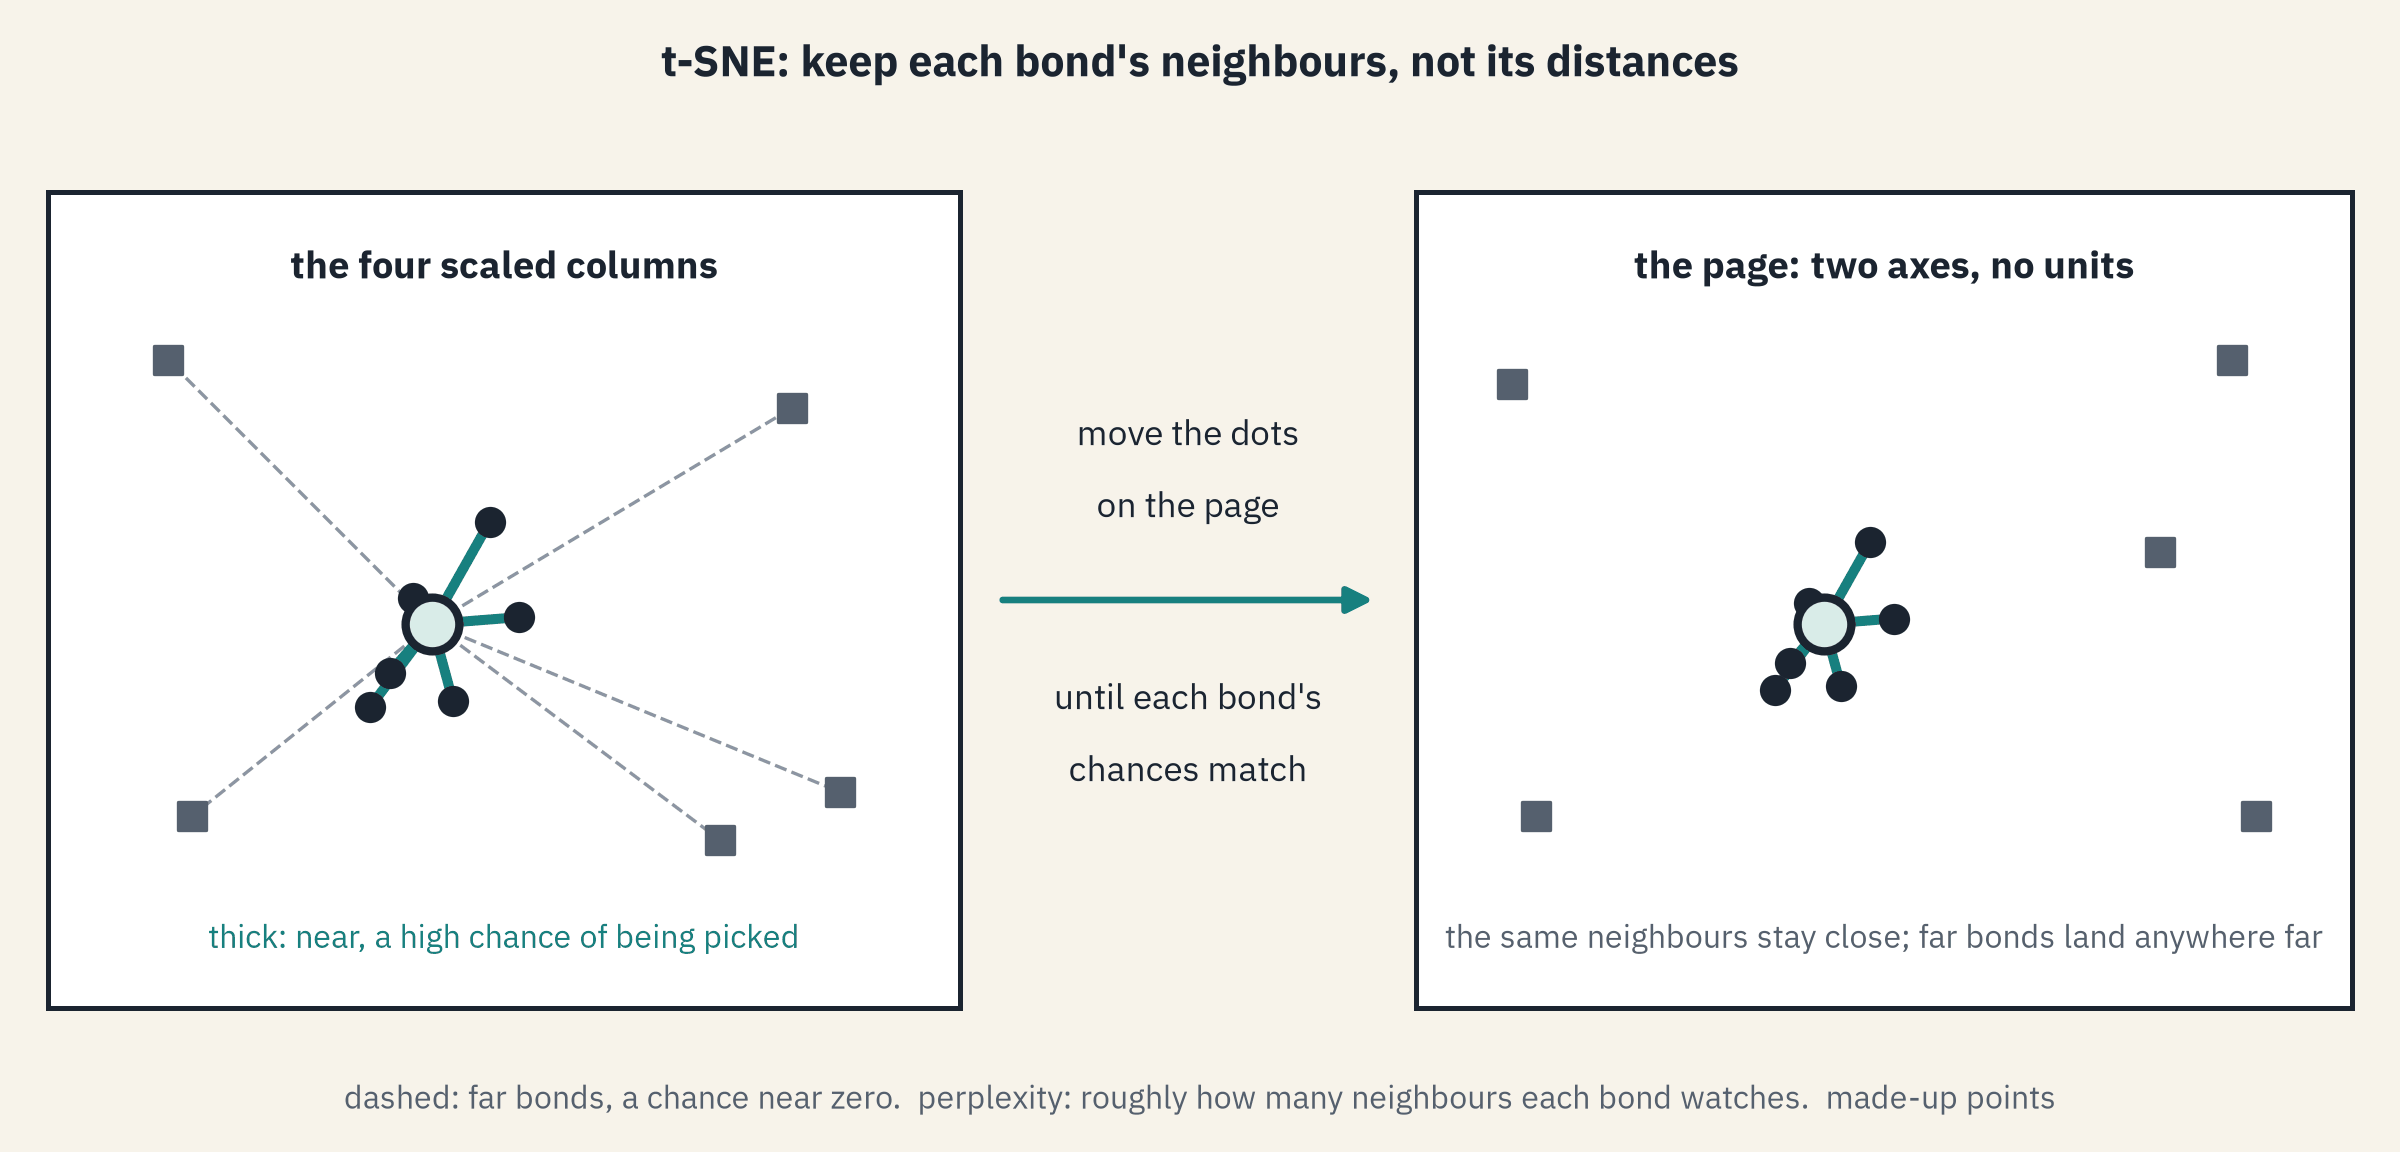)

**t-SNE** (t-distributed stochastic neighbour embedding) draws many columns on a page of two axes.

Each bond gives every other bond a chance of being its neighbour: high when near, near zero when far.

t-SNE moves the bonds on the page until the page's chances match.

**Perplexity** is roughly how many neighbours each bond watches.

The axes have no units, so coordinates are never read.

The page starts from the PCA picture (`init="pca"`), so the seed changes little.

## Three Perplexities

In [37]:
# t-SNE pictures of the 821 scaled bonds at perplexity 5, 30 and 50 (several seconds each)
pictures = {}
for perplexity in [5, 30, 50]:
    pictures[perplexity] = TSNE(n_components=2, perplexity=perplexity, random_state=SEED).fit_transform(X_bonds)

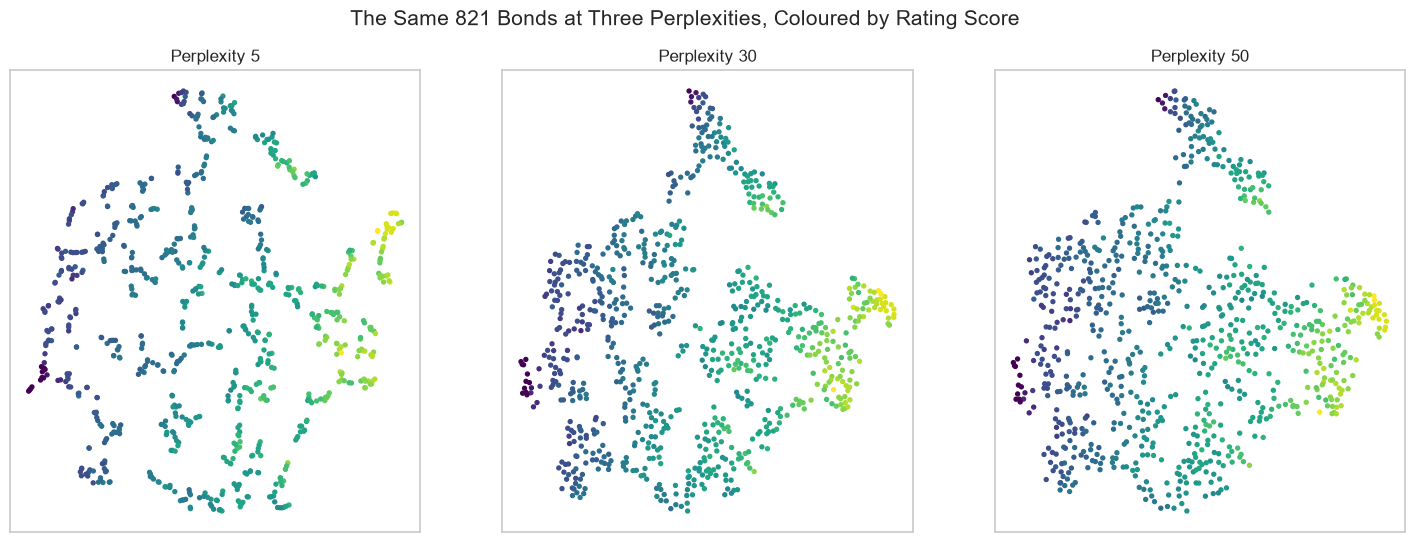

In [38]:
# one picture on one set of axes, coloured by rating score; the axes have no units, so no ticks
def draw_picture(ax, perplexity):
    points = pictures[perplexity]
    ax.scatter(points[:, 0], points[:, 1], c=bonds["score"], cmap="viridis", s=8)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f"Perplexity {perplexity}")

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, perplexity in zip(axes, [5, 30, 50]):
    draw_picture(ax, perplexity)
fig.suptitle("The Same 821 Bonds at Three Perplexities, Coloured by Rating Score", fontsize=15)
plt.show()

In every panel the colours run in bands: bonds near each other on the page have similar ratings.

The shapes change from panel to panel, with the same bonds and the same columns.

## From 2 to 200

**Predict 4**

Q. You have seen perplexity 5, 30 and 50. Sketch the pictures at perplexity 2 and 200.

In [39]:
# five more perplexities, so eight pictures in all; then your turn: pick one
for perplexity in [2, 10, 20, 100, 200]:
    pictures[perplexity] = TSNE(n_components=2, perplexity=perplexity, random_state=SEED).fit_transform(X_bonds)
perplexities = sorted(pictures)

def show_picture(perplexity=30):
    fig, ax = plt.subplots(figsize=(8, 7))
    draw_picture(ax, perplexity)
    plt.show()

interact(show_picture, perplexity=perplexities);

interactive(children=(Dropdown(description='perplexity', index=4, options=(2, 5, 10, 20, 30, 50, 100, 200), va…

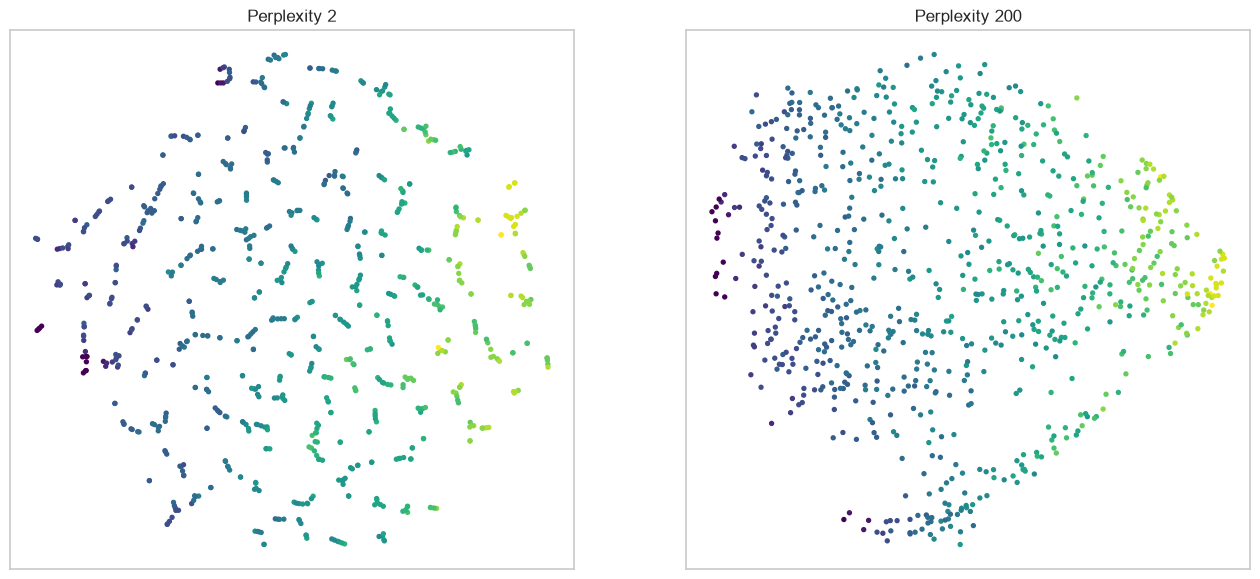

In [40]:
# perplexity 2 and 200 side by side, drawn as a still picture (the dropdown does not run on GitHub)
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
draw_picture(axes[0], 2)
draw_picture(axes[1], 200)
plt.show()

At 2, each bond watches about two neighbours: the page breaks into short strands and scattered fragments.

At 200, each bond watches about a quarter of the file: one round cloud, the groups merged.

**The picture is a choice of perplexity, so we measure which pictures keep what.**

## Which Pictures Keep Neighbours

**Trustworthiness** scores a picture from 0 to 1: 1 when every bond's 10 nearest neighbours on the page are also among its nearest in the four scaled columns.

{2: 0.9839, 5: 0.9903, 10: 0.9925, 20: 0.9931, 30: 0.9915, 50: 0.9889, 100: 0.9853, 200: 0.9724}
PCA: 0.9589


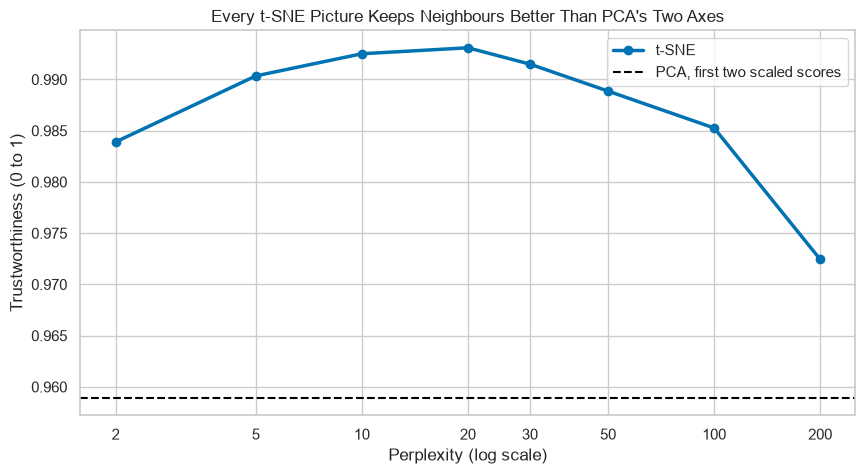

In [41]:
# trustworthiness of each t-SNE picture, and of PCA's first two scaled scores, with 10 neighbours
trust = pd.Series({p: trustworthiness(X_bonds, pictures[p], n_neighbors=10) for p in perplexities})
pca_trust = trustworthiness(X_bonds, scaled_points, n_neighbors=10)
print(trust.round(4).to_dict())
print("PCA:", round(pca_trust, 4))

# trustworthiness against perplexity on a log axis, PCA's two axes dashed
plt.plot(trust.index, trust, marker="o", linewidth=2.5, label="t-SNE")
plt.axhline(pca_trust, color="black", linestyle="--", label="PCA, first two scaled scores")
plt.xscale("log")
plt.xticks(perplexities, [str(p) for p in perplexities])
plt.minorticks_off()
plt.xlabel("Perplexity (log scale)")
plt.ylabel("Trustworthiness (0 to 1)")
plt.legend(loc="upper right")
plt.title("Every t-SNE Picture Keeps Neighbours Better Than PCA's Two Axes")
plt.show()

Trustworthiness peaks at perplexity 20, 0.9931, and is lowest at 200, 0.9724.

PCA's two axes score 0.9589, below every t-SNE picture.

## Which Pictures Keep Distances

A **Shepard diagram** puts every pair of bonds on one chart: the distance between them in the four scaled columns across, and on the page up.

In [42]:
# the distance between every pair of bonds: in the four scaled columns, on PCA's page, on t-SNE's page at 30
true_d = pdist(X_bonds)
pca_d = pdist(scaled_points)
tsne_d = pdist(pictures[30])
print(len(true_d), "pairs")
# np.corrcoef(a, b) gives the 2 x 2 table of correlations; [0, 1] is the one between a and b
print("Correlation with the true distance: PCA", round(np.corrcoef(true_d, pca_d)[0, 1], 3),
      " t-SNE at 30", round(np.corrcoef(true_d, tsne_d)[0, 1], 3))

336610 pairs
Correlation with the true distance: PCA 0.986  t-SNE at 30 0.879


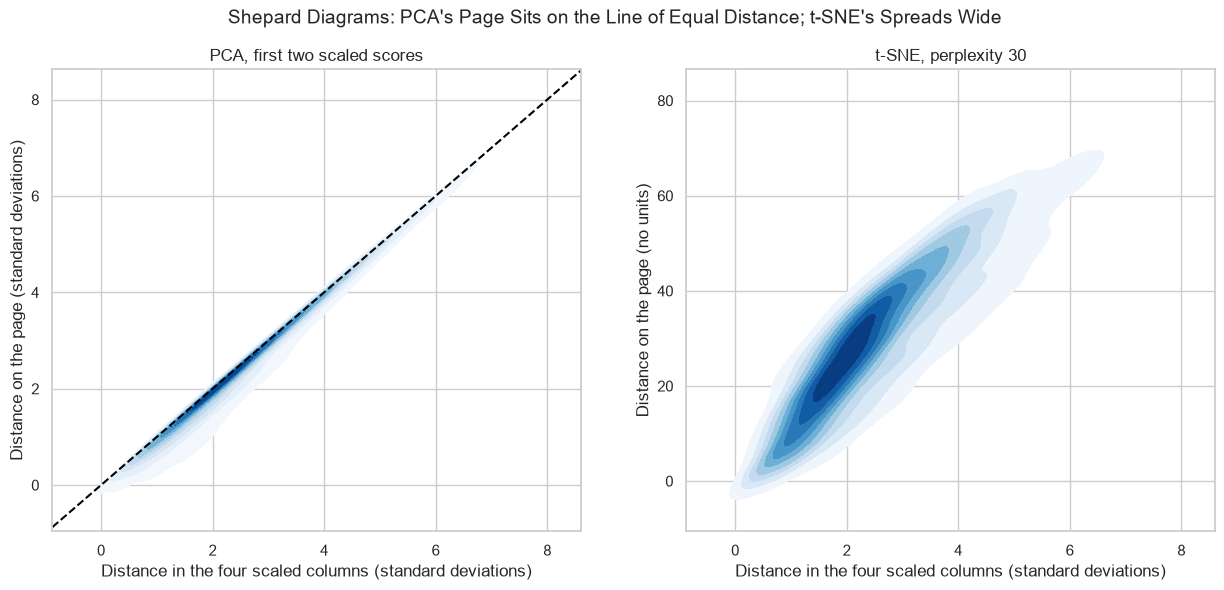

In [43]:
# 5,000 pairs drawn at random; sns.kdeplot(fill=True) shades where the pairs crowd, darker where more of them sit
rng = np.random.default_rng(SEED)
picks = rng.choice(len(true_d), size=5000, replace=False)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, page, name in zip(axes, [pca_d, tsne_d], ["PCA, first two scaled scores", "t-SNE, perplexity 30"]):
    sns.kdeplot(x=true_d[picks], y=page[picks], fill=True, cmap="Blues", ax=ax)
    ax.set_xlabel("Distance in the four scaled columns (standard deviations)")
    ax.set_title(name)
axes[0].axline((0, 0), slope=1, color="black", linestyle="--")
axes[0].set_ylabel("Distance on the page (standard deviations)")
axes[1].set_ylabel("Distance on the page (no units)")
fig.suptitle("Shepard Diagrams: PCA's Page Sits on the Line of Equal Distance; t-SNE's Spreads Wide", fontsize=14)
plt.show()

PCA's distances sit just under the dashed line of equal distance: a projection can only shorten a distance, and the order holds, correlation 0.986.

t-SNE's correlation is 0.879: pairs at one true distance land across a wide band on the page, so a gap between groups means little.

## Day 12's Clusters on Both Pictures

Q. Do Day 12's four clusters look the same on both pictures?

In [44]:
# Day 12's colours, numbering and model, repeated as Day 12 wrote them
# color_palette() hands back the set's colours, and as_hex() writes each one as a text code plotly also reads
colours = sns.color_palette("colorblind").as_hex()
colours = [colours[i] for i in [0, 1, 2, 4, 3]]

# number the clusters by size: the largest becomes cluster 0
def by_size(labels):
    sizes = pd.Series(labels).value_counts()
    new_number = {old: new for new, old in enumerate(sizes.index)}
    return pd.Series(labels).map(new_number)

# the four clusters on the scaled columns
kmeans = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X_bonds)
cluster = by_size(kmeans.labels_)
cluster.value_counts().to_dict()

{0: 278, 1: 239, 2: 175, 3: 129}

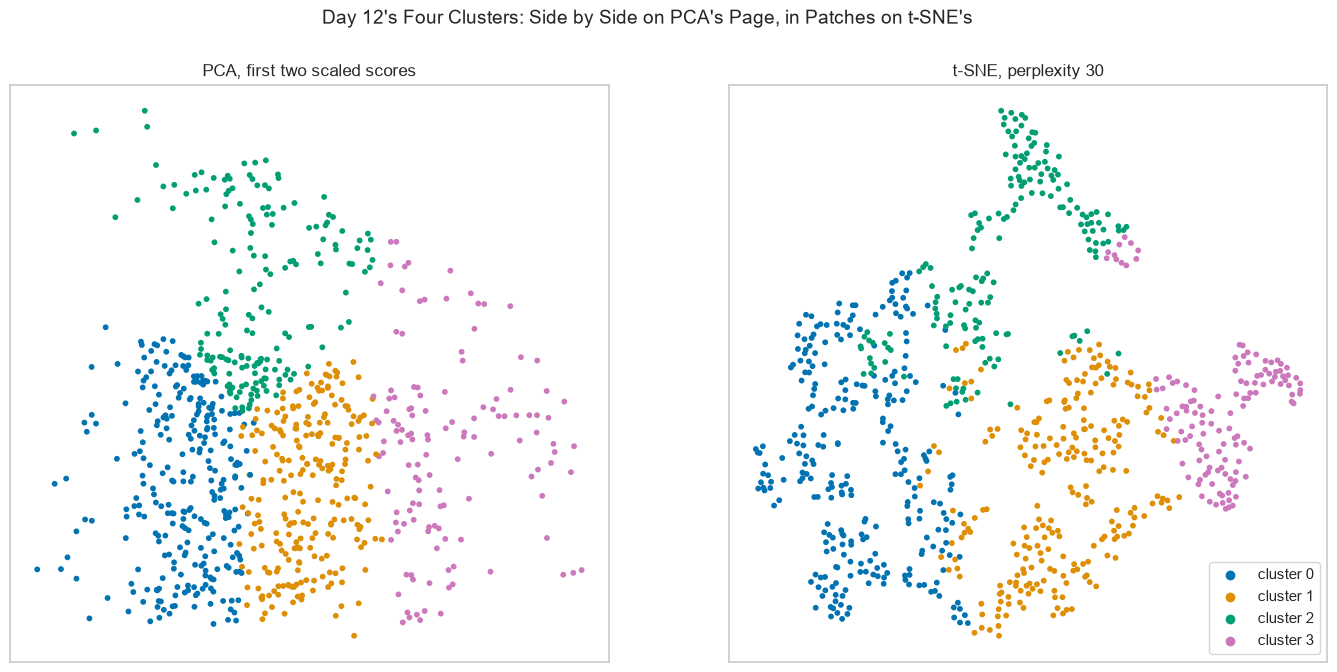

In [45]:
# PCA's page and t-SNE's page at 30, each bond coloured by its cluster
fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))
for ax, points, name in [(axes[0], scaled_points.to_numpy(), "PCA, first two scaled scores"), (axes[1], pictures[30], "t-SNE, perplexity 30")]:
    ax.scatter(points[:, 0], points[:, 1], c=[colours[c] for c in cluster], s=10)
    ax.set_title(name)
    ax.set_xticks([])
    ax.set_yticks([])
# empty scatters: one legend entry per cluster, no dots on the chart
for number in range(4):
    axes[1].scatter([], [], color=colours[number], label=f"cluster {number}")
axes[1].legend(loc="lower right")
fig.suptitle("Day 12's Four Clusters: Side by Side on PCA's Page, in Patches on t-SNE's", fontsize=14)
plt.show()

On PCA's page the four clusters sit side by side and meet at their edges, cluster 2's long bonds at the top.

On t-SNE's page every cluster breaks into patches: cluster 2 sits in two places far apart, and a few of cluster 3's bonds sit at the tip of cluster 2's arm.

**PCA keeps distances, t-SNE keeps neighbours: read a t-SNE picture for who sits near whom, never for how far or how big.**

# Insights and Conclusion

Level, slope and curvature carry 99.86 percent of the variance in the curve's levels since 2015.

Names come from loadings: on daily changes the third shape is the 1 Yr alone.

Three scores rebuild a date to 4.35 bp on average, and two draw the curve's whole path.

PCA that builds features is fitted inside each fold; fitted on the whole file it uses later rows.

Mixed units are scaled before PCA, or the largest unit takes an axis.

t-SNE keeps neighbours better than PCA and distances worse.

All of it describes the file's history; no component says what rates will do.

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Fit PCA, read a scree plot, and fix each component's sign.
* Name a component from its loadings, and chart its scores as history.
* Rebuild rows from k components with `inverse_transform`.
* Keep PCA inside a pipeline and show a step has no lookahead.
* Scale mixed units before PCA, and draw a biplot.
* Draw t-SNE pictures and judge them with trustworthiness and a Shepard diagram.

## Exercises

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [46]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**The Curve Without the Bills**

Q. Fit PCA to the levels of the 2 Yr to the 30 Yr only, every date, and store the percent of the variance PC1 carries in `ex1_pc1_pct`.

In [47]:
# PCA on the seven tenors from the 2 Yr out, every date
long_end = levels[["2 Yr", "3 Yr", "5 Yr", "7 Yr", "10 Yr", "20 Yr", "30 Yr"]]
ex1_pc1_pct = explained_table(PCA().fit(long_end)).loc["PC1", "explained_pct"]
print(round(ex1_pc1_pct, 2))

97.24


Without the bills, PC1 carries 97.24 percent of the variance, against 95.62 with all eleven tenors.

The short end is the part of the curve that moved most on its own.

In [48]:
check("Exercise 1 PC1 of the 2 Yr to 30 Yr levels", ex1_pc1_pct, 97.23707819875297)

Exercise 1 PC1 of the 2 Yr to 30 Yr levels: correct


### Exercise 2

**Two Halves of the File**

Q. Fit PCA to the daily changes of 2015 to 2019 (`changes.loc["2015":"2019"]`) and of 2022 to 2026. Store a dictionary with the keys `"2015 to 2019"` and `"2022 to 2026"` and each period's PC1 percent, rounded to 2 decimals, in `ex2_pc1_by_period`.

In [49]:
# PC1's share of the daily variance in each half of the file
ex2_pc1_by_period = {}
for name, rows in [("2015 to 2019", changes.loc["2015":"2019"]), ("2022 to 2026", changes.loc["2022":"2026"])]:
    ex2_pc1_by_period[name] = round(float(explained_table(PCA().fit(rows)).loc["PC1", "explained_pct"]), 2)
print(ex2_pc1_by_period)

{'2015 to 2019': 87.68, '2022 to 2026': 86.7}


PC1 carries 87.68 percent of the daily variance in 2015 to 2019 and 86.70 in 2022 to 2026.

The two halves agree closely: in both, most days moved the curve mostly in one piece.

In [50]:
check("Exercise 2 PC1 by period", ex2_pc1_by_period, {"2015 to 2019": 87.68, "2022 to 2026": 86.7})

Exercise 2 PC1 by period: correct


### Exercise 3

**How Many Components**

Q. Write `components_for(pca, share)`: the smallest number of components whose running total reaches `share` percent. Store its results on `pca_changes` for 95, 98 and 99, as a list, in `ex3_counts`.

In [51]:
# the components whose running total is still short of the share, plus one
def components_for(pca, share):
    cumulative = explained_table(pca)["cumulative_pct"]
    return int((cumulative < share).sum()) + 1

ex3_counts = [components_for(pca_changes, share) for share in [95, 98, 99]]
print(ex3_counts)

[2, 3, 5]


Two components reach 95 percent of the daily variance, three reach 98, and five reach 99.

The last percent takes as many components as the first 98.

In [52]:
check("Exercise 3 components for 95, 98 and 99 percent", ex3_counts, [2, 3, 5])

Exercise 3 components for 95, 98 and 99 percent: correct


### Exercise 4: AI check

**One Fold, Scored Faster**

You asked an AI assistant for the first walk-forward fold's MAE of three components then a line.
This came back.
It runs, and its number is close to the pipeline's.

In [53]:
# the first fold's training and test positions
train_first, test_first = list(wf.split(X))[0]

# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def first_fold_mae(rows):
    # fit the components once on the history so they are as stable as possible, then a line on the training dates
    pca_once = PCA(n_components=3).fit(rows[tenors[:-1]])
    line = LinearRegression().fit(pca_once.transform(rows[tenors[:-1]].iloc[train_first]), rows["30 Yr"].iloc[train_first])
    fitted = line.predict(pca_once.transform(rows[tenors[:-1]].iloc[test_first]))
    return np.abs(rows["30 Yr"].iloc[test_first] - fitted).mean()

# the check: the same fold with every row after it deleted, and the pipeline's first fold
print("First fold MAE:", round(first_fold_mae(changes), 3), "bp")
print("With every later row deleted:", round(first_fold_mae(changes.iloc[:test_first[-1] + 1]), 3), "bp")
print("The pipeline's first fold:", round(pca_mae[0], 3), "bp")

First fold MAE: 0.719 bp
With every later row deleted: 0.717 bp
The pipeline's first fold: 0.713 bp


Q. Why does deleting rows after the fold change the fold's MAE? Fix the one wrong line, and store the fixed function's MAE on `changes` in `ex4_fold_mae_bp`.

In [54]:
# the fix: fit the components on the fold's training dates only, as the pipeline does
def first_fold_mae(rows):
    pca_once = PCA(n_components=3).fit(rows[tenors[:-1]].iloc[train_first])
    line = LinearRegression().fit(pca_once.transform(rows[tenors[:-1]].iloc[train_first]), rows["30 Yr"].iloc[train_first])
    fitted = line.predict(pca_once.transform(rows[tenors[:-1]].iloc[test_first]))
    return np.abs(rows["30 Yr"].iloc[test_first] - fitted).mean()

ex4_fold_mae_bp = first_fold_mae(changes)
print(round(ex4_fold_mae_bp, 3), round(first_fold_mae(changes.iloc[:test_first[-1] + 1]), 3))

0.713 0.713


The bug is the fit line: `PCA(...).fit(rows[...])` fits the components on every date in `rows`, years after the fold's test dates.

Deleting the later rows moved the number from 0.719 to 0.717 bp, so the later rows were inside it.

Fitted on the training dates only, the MAE is 0.713 bp, the pipeline's first fold, with or without the later rows.

The leaky number was barely different: lookahead changes what a number means, not always its size.

In [55]:
check("Exercise 4 the fixed first fold MAE", ex4_fold_mae_bp, 0.7133727688376537)

Exercise 4 the fixed first fold MAE: correct


## Congratulations!

You turned eleven yields into three numbers a day and let the file name its own shapes.
You read level, slope and curvature off the loadings and drew the curve's whole path from 2015 to 2026.
You caught a whole-file PCA using later rows and put it inside a pipeline.
Then you drew 821 bonds with t-SNE and measured what the picture keeps and what it throws away.
On Day 15 the capstone puts the whole course to work on one real file.

[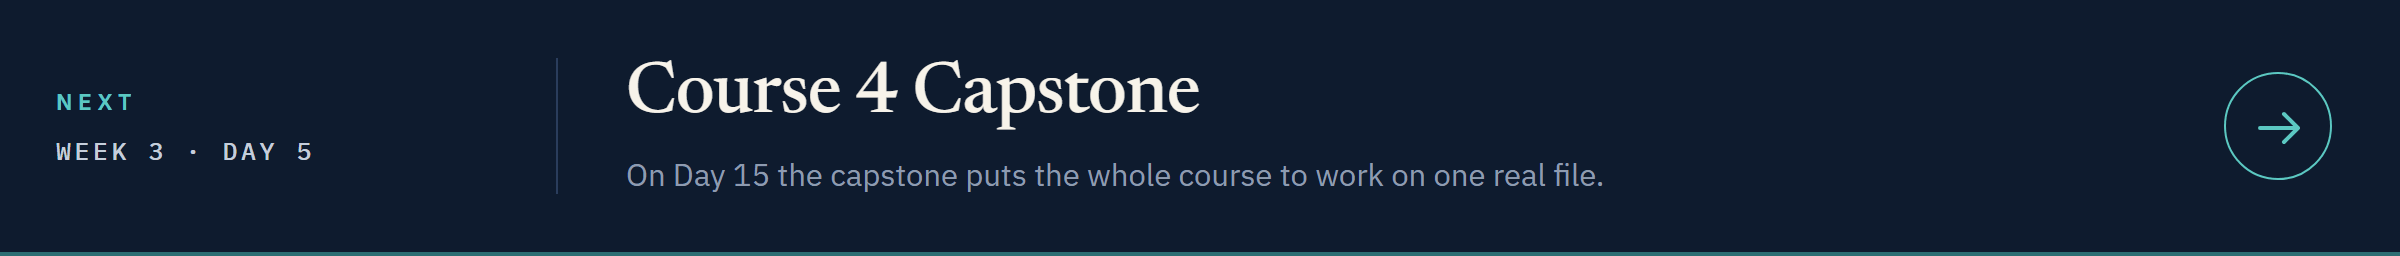](../day5/course4_capstone.ipynb)

[Open Day 5 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course04_machine_learning/week3/day5/course4_capstone.ipynb)